# Milestone 1: Formula 1 Podium Prediction Companion
**Part A — Setup, Audit, Cleaning, Grain & Key Integrity**

Notebook map (later parts will be added below):
1. Setup & data loading (raw files are never modified)
2. EDA **before** cleaning (sentinels, missingness, duplicates)
3. Cleaning: sentinels `\N`, semantic typing (dates, lap times)
4. Grain: one row per `(raceId, driverId)` + duplicate rule
5. Primary-key / foreign-key validation
6. EDA **after** cleaning (impact of the cleaning)


## 1. Setup & loading

In [38]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
SEED = 42
np.random.seed(SEED)


DATA_DIR = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"
if not os.path.exists(DATA_DIR):                       # fallback if folder name differs
    for root, _, files in os.walk("/kaggle/input"):
        if "results.csv" in files:
            DATA_DIR = root; break
print("Using:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

Using: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
['circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


In [39]:
TABLES = ["circuits","constructor_results","constructor_standings","constructors","driver_standings",
          "drivers","lap_times","pit_stops","qualifying","races","results","seasons","sprint_results","status"]

# RAW copy: everything as string, nothing auto-converted -> lets us audit the \N sentinels honestly
raw = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", dtype=str, keep_default_na=False) for t in TABLES if os.path.exists(f"{DATA_DIR}/{t}.csv")}
pd.DataFrame({t: {"rows": len(d), "cols": d.shape[1]} for t, d in raw.items()}).T

,rows,cols
circuits,77,9
constructor_results,12625,5
constructor_standings,13391,7
constructors,212,5
driver_standings,34863,7
drivers,861,9
lap_times,589081,6
pit_stops,11371,7
qualifying,10494,9
races,1125,18


## 2. EDA before cleaning
**Why:** in these CSVs missing values are encoded as the literal string `\N`, so `isna()` on the raw load reports *zero* missing , misleading. We count the sentinel explicitly, and later compare with the cleaned tables.

,table,column,n_sentinel,pct
0,constructor_results,status,12608,99.865347
16,races,sprint_time,1110,98.666667
15,races,sprint_date,1107,98.400000
12,races,fp3_time,1072,95.288889
8,races,fp1_time,1057,93.955556
10,races,fp2_time,1057,93.955556
14,races,quali_time,1057,93.955556
11,races,fp3_date,1053,93.600000
1,drivers,number,802,93.147503
7,races,fp1_date,1035,92.000000


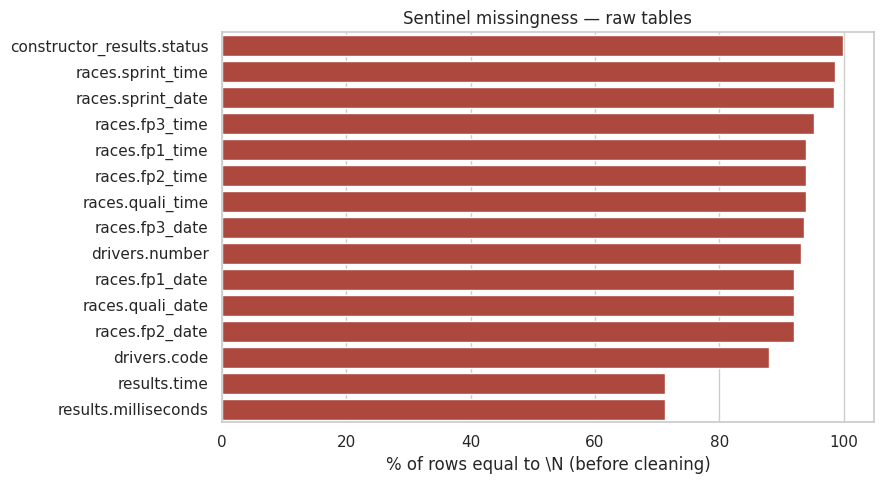

In [40]:
SENT = r"\N"
sent_counts = []
for t, d in raw.items():
    for c in d.columns:
        n = ((d[c] == SENT) | (d[c].str.strip() == "")).sum()
        if n: sent_counts.append((t, c, n, 100*n/len(d)))
sent_df = pd.DataFrame(sent_counts, columns=["table","column","n_sentinel","pct"]).sort_values("pct", ascending=False)
display(sent_df.head(25))

top = sent_df.head(15).copy(); top["label"] = top.table + "." + top.column
plt.figure(figsize=(9,5))
sns.barplot(data=top, y="label", x="pct", color="#c0392b")
plt.xlabel("% of rows equal to \\N (before cleaning)"); plt.ylabel(""); plt.title("Sentinel missingness — raw tables")
plt.tight_layout(); plt.show()

## 3. Cleaning (on copies): sentinels + semantic typing

**Principle:** raw CSVs are never modified. All cleaning is applied to in-memory copies (`dfs`), while `raw` keeps the untouched strings for auditing.

| Choice | Justification (F1 podium task) |
|---|---|
| **`\N` → `NaN` via `na_values=["\\N"]`** | The dataset encodes "missing" as the literal text `\N`, so pandas reads those columns as strings and `isna()` reports zero missing (Section 2 proved this). Converting to real `NaN` makes missingness countable, plottable and imputable, and lets numeric columns be parsed as numbers. |
| **`keep_default_na=False`** | By default pandas also treats strings like `"NA"` or `"null"` as missing. In F1 data these can be legitimate values (e.g. a code or nationality), so only the dataset's own sentinel is converted. This avoids silently creating false missing values. |
| **Dates → `datetime`** (`races.date`, `drivers.dob`) | Strings cannot be ordered or subtracted. Real dates are needed for time-based splitting, for sorting races chronologically (required by the leakage-safe "past races only" form features) and for computing driver age at race time. |
| **Lap/qualifying times → float seconds** (`q1/q2/q3`, `fastestLapTime`, pit `duration`) | Times like `1:27.452` are text and can't be compared or averaged. Seconds are numeric, so we can compute gaps to pole, rank drivers and feed them to models. `to_seconds()` returns `NaN` on unparseable values rather than guessing. |
| **Numeric coercion** (`grid`, `positionOrder`, `points`, `laps`, …) | Guarantees correct dtypes after sentinel removal. `errors="coerce"` turns bad values into `NaN` instead of crashing. We check this by printing the parse-failure count. |
| **`NaN` kept, not filled, at this stage** | Missingness is informative here (e.g. no Q3 time usually means elimination in Q1/Q2, and qualifying data is absent in early seasons). Imputation is deferred to the modeling pipeline, fitted on training data only, to avoid leakage. |

**Verification:** the cell prints the number of qualifying-time parse failures and sample converted rows. Section 6 plots missingness and the lap-time distribution after cleaning to show the effect.


## 3. Cleaning (on copies): sentinels + semantic typing

In [41]:
# CLEAN copy: \N -> NaN. keep_default_na=False so legit strings (e.g. "NA") are NOT silently turned into NaN.
dfs = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", na_values=[SENT, ""], keep_default_na=False) for t in raw}
def to_seconds(s):
    # 'm:ss.mmm' or 'ss.mmm' -> float seconds ; NaN stays NaN
    if pd.isna(s): return np.nan
    s = str(s).strip()
    try:
        if ":" in s:
            parts = s.split(":")
            return sum(float(p) * 60**i for i, p in enumerate(reversed(parts)))
        return float(s)
    except ValueError:
        return np.nan

# --- dates ---
dfs["races"]["date"]   = pd.to_datetime(dfs["races"]["date"], errors="coerce")
dfs["drivers"]["dob"]  = pd.to_datetime(dfs["drivers"]["dob"], errors="coerce")

# --- durations -> seconds ---
for c in ["q1","q2","q3"]:
    dfs["qualifying"][c+"_sec"] = dfs["qualifying"][c].map(to_seconds)
dfs["results"]["fastestLapTime_sec"] = dfs["results"]["fastestLapTime"].map(to_seconds)
if "duration" in dfs["pit_stops"]:
    dfs["pit_stops"]["duration_sec"] = dfs["pit_stops"]["duration"].map(to_seconds)

# --- numeric columns that may have been read as object because of other junk ---
for c in ["position","grid","positionOrder","points","laps","milliseconds","rank","number","fastestLap"]:
    if c in dfs["results"]:
        dfs["results"][c] = pd.to_numeric(dfs["results"][c], errors="coerce")

# --- sanity checks on conversion ---
print("Qualifying q3 parse-failures:", (dfs["qualifying"].q3.notna() & dfs["qualifying"].q3_sec.isna()).sum())
print(dfs["qualifying"][["q1","q1_sec","q3","q3_sec"]].dropna().head(3))
dfs["races"][["year","date"]].dtypes

Qualifying q3 parse-failures: 0
         q1  q1_sec        q3  q3_sec
0  1:26.572  86.572  1:26.714  86.714
1  1:26.103  86.103  1:26.869  86.869
2  1:25.664  85.664  1:27.079  87.079


year             int64
date    datetime64[ns]
dtype: object

## 4. Grain: one row per `(raceId, driverId)`
Each modeling row = *"will this driver podium in this race?"*, so `(raceId, driverId)` must be unique.
Check `results` (and `qualifying`) for duplicates first.

results rows: 26,759 | rows involved in duplicates: 176 | duplicated (raceId,driverId) pairs: 85


,raceId,year,name,driverId,constructorId,grid,positionOrder,laps,statusId
0,540,1978,Italian Grand Prix,229,54,0,26,0,81
1,540,1978,Italian Grand Prix,229,57,0,29,0,97
2,717,1964,United States Grand Prix,373,172,1,7,102,60
175,717,1964,United States Grand Prix,373,172,1,12,54,98
3,733,1962,British Grand Prix,465,172,0,22,0,54
4,733,1962,British Grand Prix,465,97,0,25,0,54
5,742,1961,British Grand Prix,475,102,20,19,56,2
6,742,1961,British Grand Prix,475,172,5,21,44,23
174,745,1961,United States Grand Prix,418,172,15,11,92,18
7,745,1961,United States Grand Prix,418,172,11,17,23,6


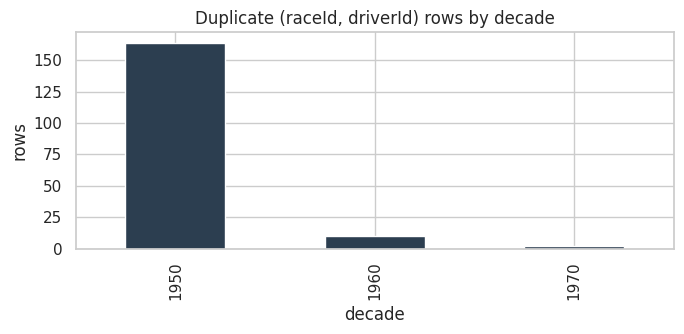

qualifying duplicates on (raceId, driverId): 0


In [42]:
res = dfs["results"].copy()
dup_mask = res.duplicated(["raceId","driverId"], keep=False)
dups = res[dup_mask].merge(dfs["races"][["raceId","year","name"]], on="raceId").sort_values(["raceId","driverId","positionOrder"])
print(f"results rows: {len(res):,} | rows involved in duplicates: {dup_mask.sum()} | duplicated (raceId,driverId) pairs: {dups.groupby(['raceId','driverId']).ngroups}")
display(dups[["raceId","year","name","driverId","constructorId","grid","positionOrder","laps","statusId"]].head(10))

dups["decade"] = (dups.year//10)*10
dups.groupby("decade").size().plot(kind="bar", color="#2c3e50", figsize=(7,3.5))
plt.title("Duplicate (raceId, driverId) rows by decade"); plt.ylabel("rows"); plt.tight_layout(); plt.show()

q = dfs["qualifying"]
print("qualifying duplicates on (raceId, driverId):", q.duplicated(["raceId","driverId"]).sum())

**Dedup rule:** for a shared drive, keep the row with the **best `positionOrder`** (tie → more `laps`, tie → lowest `resultId`).

*Why:* the target is `positionOrder <= 3`; a driver who shared a podium-finishing car genuinely stood on that podium (points were shared), so keeping the best-classified row preserves that label instead of randomly dropping it. Alternatives (keep first / keep most laps) are weaker for the target definition.

In [43]:
res = res.sort_values(["raceId","driverId","positionOrder","laps","resultId"], ascending=[True,True,True,False,True])
res_dedup = res.drop_duplicates(["raceId","driverId"], keep="first").sort_values("resultId").reset_index(drop=True)
assert not res_dedup.duplicated(["raceId","driverId"]).any()
print(f"before: {len(res):,}  after: {len(res_dedup):,}  removed: {len(res)-len(res_dedup)}")
dfs["results"] = res_dedup

# podium target (label only — NEVER a feature)
dfs["results"]["podium"] = (dfs["results"]["positionOrder"] <= 3).astype(int)
print("Podium rate:", dfs["results"]["podium"].mean().round(4))

before: 26,759  after: 26,668  removed: 91
Podium rate: 0.1273


## 5. Primary-key & foreign-key validation

In [44]:
PKS = {"circuits":["circuitId"],"constructors":["constructorId"],"drivers":["driverId"],"races":["raceId"],
       "results":["resultId"],"qualifying":["qualifyId"],"status":["statusId"],"seasons":["year"],
       "constructor_results":["constructorResultsId"],"constructor_standings":["constructorStandingsId"],
       "driver_standings":["driverStandingsId"],"sprint_results":["resultId"],
       "lap_times":["raceId","driverId","lap"],"pit_stops":["raceId","driverId","stop"]}

rows = []
for t, pk in PKS.items():
    if t not in dfs: continue
    d = dfs[t]
    rows.append({"table":t, "pk":pk, "n_null_in_pk": int(d[pk].isna().any(axis=1).sum()),
                 "n_duplicate_pk": int(d.duplicated(pk).sum()), "ok": (d[pk].isna().sum().sum()==0) and (not d.duplicated(pk).any())})
pk_report = pd.DataFrame(rows); display(pk_report)

FKS = [("results","raceId","races","raceId"),("results","driverId","drivers","driverId"),
       ("results","constructorId","constructors","constructorId"),("results","statusId","status","statusId"),
       ("qualifying","raceId","races","raceId"),("qualifying","driverId","drivers","driverId"),
       ("qualifying","constructorId","constructors","constructorId"),
       ("races","circuitId","circuits","circuitId"),("races","year","seasons","year"),
       ("driver_standings","raceId","races","raceId"),("driver_standings","driverId","drivers","driverId"),
       ("constructor_standings","constructorId","constructors","constructorId"),
       ("lap_times","raceId","races","raceId"),("pit_stops","raceId","races","raceId"),
       ("sprint_results","raceId","races","raceId")]
rows = []
for ct, cc, pt, pc in FKS:
    if ct not in dfs or pt not in dfs: continue
    child = dfs[ct][cc].dropna()
    orphans = (~child.isin(dfs[pt][pc])).sum()
    rows.append({"child":f"{ct}.{cc}", "parent":f"{pt}.{pc}", "n_checked":len(child), "n_orphans":int(orphans), "ok": orphans==0})
fk_report = pd.DataFrame(rows); display(fk_report)

,table,pk,n_null_in_pk,n_duplicate_pk,ok
0,circuits,[circuitId],0,0,True
1,constructors,[constructorId],0,0,True
2,drivers,[driverId],0,0,True
3,races,[raceId],0,0,True
4,results,[resultId],0,0,True
5,qualifying,[qualifyId],0,0,True
6,status,[statusId],0,0,True
7,seasons,[year],0,0,True
8,constructor_results,[constructorResultsId],0,0,True
9,constructor_standings,[constructorStandingsId],0,0,True


,child,parent,n_checked,n_orphans,ok
0,results.raceId,races.raceId,26668,0,True
1,results.driverId,drivers.driverId,26668,0,True
2,results.constructorId,constructors.constructorId,26668,0,True
3,results.statusId,status.statusId,26668,0,True
4,qualifying.raceId,races.raceId,10494,0,True
5,qualifying.driverId,drivers.driverId,10494,0,True
6,qualifying.constructorId,constructors.constructorId,10494,0,True
7,races.circuitId,circuits.circuitId,1125,0,True
8,races.year,seasons.year,1125,0,True
9,driver_standings.raceId,races.raceId,34863,0,True


## 6. EDA after cleaning — impact of cleaning

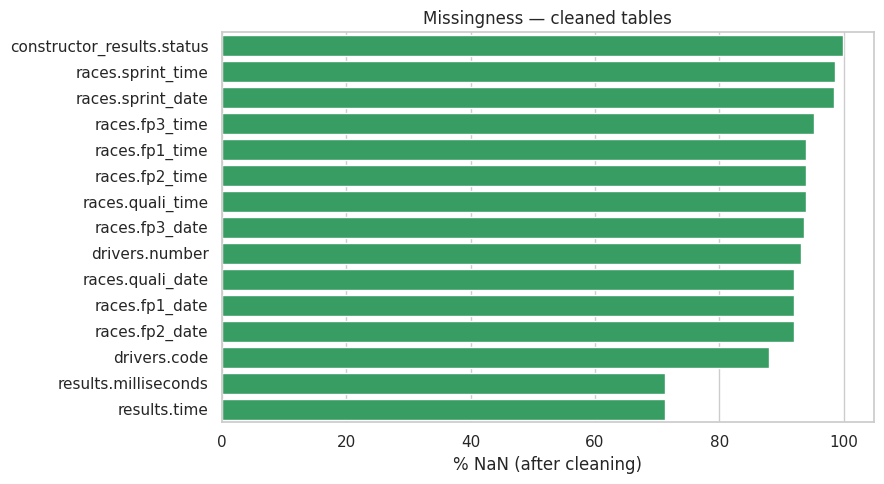

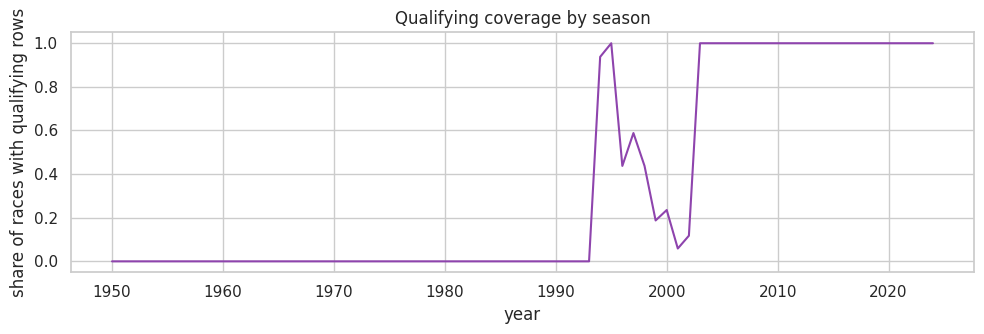

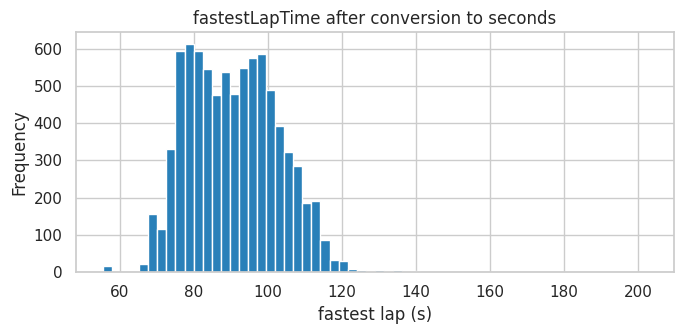

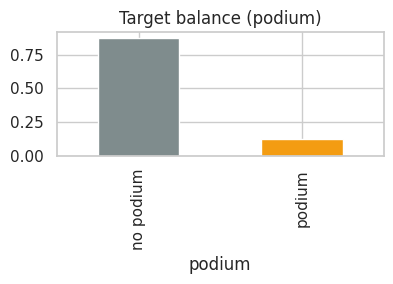

In [45]:
# (a) missingness now visible as real NaN (compare with the raw sentinel plot in Section 2)
after = []
for t, d in dfs.items():
    for c in d.columns:
        n = d[c].isna().sum()
        if n: after.append((t, c, 100*n/len(d)))
after_df = pd.DataFrame(after, columns=["table","column","pct"]).sort_values("pct", ascending=False)
top = after_df.head(15).copy(); top["label"] = top.table + "." + top.column
plt.figure(figsize=(9,5)); sns.barplot(data=top, y="label", x="pct", color="#27ae60")
plt.xlabel("% NaN (after cleaning)"); plt.ylabel(""); plt.title("Missingness — cleaned tables"); plt.tight_layout(); plt.show()

# (b) qualifying coverage drift over seasons (needed later for features + limitations section)
cov = (dfs["qualifying"].merge(dfs["races"][["raceId","year"]], on="raceId")
         .groupby("year").raceId.nunique() / dfs["races"].groupby("year").raceId.nunique()).fillna(0)
plt.figure(figsize=(10,3.5)); cov.plot(color="#8e44ad"); plt.ylabel("share of races with qualifying rows")
plt.title("Qualifying coverage by season"); plt.tight_layout(); plt.show()

# (c) before/after on lap-time column: string -> numeric seconds
r = dfs["results"]
r["fastestLapTime_sec"].dropna().plot(kind="hist", bins=60, figsize=(7,3.5), color="#2980b9")
plt.xlabel("fastest lap (s)"); plt.title("fastestLapTime after conversion to seconds"); plt.tight_layout(); plt.show()

# (d) target balance
r["podium"].value_counts(normalize=True).rename({0:"no podium",1:"podium"}).plot(kind="bar", color=["#7f8c8d","#f39c12"], figsize=(4,3))
plt.title("Target balance (podium)"); plt.tight_layout(); plt.show()

Interpretation. Most real missingness is structural: sprint, practice and qualifying schedule fields (around 90-100% NaN) exist only for recent seasons, and results.time/milliseconds (around 70% NaN) exist only for finishers on the lead lap, so these are flagged or dropped rather than imputed. Qualifying coverage is zero before 1994, patchy from 1994 to 2002, and complete from 2003 onward, so qualifying-derived features are only valid from 2003. The podium rate is about 12% (3 podium places among ~20+ starters per race), a rare-positive problem, so models are evaluated with PR-AUC, recall and F1 rather than accuracy. Fastest-lap times converted cleanly to seconds, with values mostly between 75 and 120 s.

In [46]:
# Keep cleaned tables in memory (raw CSVs remain untouched in /kaggle/input)
clean = dfs
print({k: v.shape for k, v in clean.items()})

{'circuits': (77, 9), 'constructor_results': (12625, 5), 'constructor_standings': (13391, 7), 'constructors': (212, 5), 'driver_standings': (34863, 7), 'drivers': (861, 9), 'lap_times': (589081, 6), 'pit_stops': (11371, 8), 'qualifying': (10494, 12), 'races': (1125, 18), 'results': (26668, 20), 'seasons': (75, 2), 'sprint_results': (360, 16), 'status': (139, 2)}


# Part B — Data-Engineering Questions (Q1–Q3)
* these cells use the cleaned tables in `dfs`.*

## 0. Shared analytical base table
**Grain:** one row per `(raceId, driverId)` (deduplicated in Part A). We enrich it with multi-hop joins:
`results → races (year, circuit) → circuits (country)`, `results → qualifying (quali position)`, `results → drivers (nationality)`, `results → constructors (name)`.
All joins are many-to-one (or one-to-one) on keys validated in Section 5, so the row count must not change — asserted below.

In [47]:
import re
from scipy.stats import spearmanr
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable

res = dfs["results"][["raceId","driverId","constructorId","grid","positionOrder","statusId","laps","podium"]].copy()
rc  = dfs["races"][["raceId","year","round","circuitId","name"]].rename(columns={"name":"race_name"})
ci  = dfs["circuits"][["circuitId","name","country"]].rename(columns={"name":"circuit_name","country":"circuit_country"})
qa  = dfs["qualifying"][["raceId","driverId","position"]].rename(columns={"position":"quali_pos"})
qa["quali_pos"] = pd.to_numeric(qa["quali_pos"], errors="coerce")
qa  = qa.sort_values(["raceId","driverId","quali_pos"]).drop_duplicates(["raceId","driverId"])   # 1 row per (race, driver)
dr  = dfs["drivers"][["driverId","nationality"]]
co  = dfs["constructors"][["constructorId","name"]].rename(columns={"name":"constructor_name"})

base = (res.merge(rc, on="raceId", how="left").merge(ci, on="circuitId", how="left")
           .merge(qa, on=["raceId","driverId"], how="left")
           .merge(dr, on="driverId", how="left").merge(co, on="constructorId", how="left"))
assert len(base) == len(res), "a join changed the grain"
assert not base.duplicated(["raceId","driverId"]).any()

# Missingness / coverage summary of the join keys we rely on (justification of grain + missingness)
miss = pd.DataFrame({
    "missing_%": [100*base.quali_pos.isna().mean(), 100*(base.grid==0).mean(),
                  100*base.circuit_country.isna().mean(), 100*base.nationality.isna().mean(), 100*base.constructor_name.isna().mean()]},
    index=["quali_pos missing (no qualifying data)", "grid == 0 (no normal grid slot)", "circuit_country", "driver nationality", "constructor name"])
display(miss.round(2))

,missing_%
quali_pos missing (no qualifying data),60.65
grid == 0 (no normal grid slot),6.13
circuit_country,0.00
driver nationality,0.00
constructor name,0.00


In [48]:
def wilson(k, n, z=1.96):
    # 95% Wilson interval for a proportion k/n (stable for small n, unlike the normal approximation)
    k = np.asarray(k, float); n = np.asarray(n, float); p = k/n
    d = 1 + z**2/n; c = (p + z**2/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n + z**2/(4*n**2))/d
    return c-h, c+h

# Q1. Which circuits convert a front-row start into a podium most often — and does the ranking change after 2014?

**Method**
- *Qualifying position* (`qualifying.position`) and *grid position* (`results.grid`) are different: grid is the qualifying order **after penalties**. We define two front-row flags: `fr_quali = quali_pos <= 2`, `fr_grid = grid <= 2`, and report both.
- **Conversion rate** = podiums ÷ front-row starts, per circuit, with a 95 % Wilson interval. Circuits with too few front-row starts are excluded (a 2/2 record is not a ranking).
- **Era split:** pre-2014 vs 2014+ (hybrid era).

**Grain:** one row = one driver start. **Missingness:** qualifying rows don't exist for early seasons, so we restrict to races that have qualifying data, and `grid == 0` rows (no normal grid slot) are excluded. Using the *same* races for both definitions keeps them comparable.
**Pre-race cutoff:** qualifying position and grid are both known before the lights go out; the podium is only the outcome we measure.

rows: 10,407 | seasons 1994–2024 | races: 494


fr_grid,False,True,All
fr_quali,,,
False,9385,36,9421
True,36,950,986
All,9421,986,10407


0.7% of starters have a different front-row status under qualifying vs grid


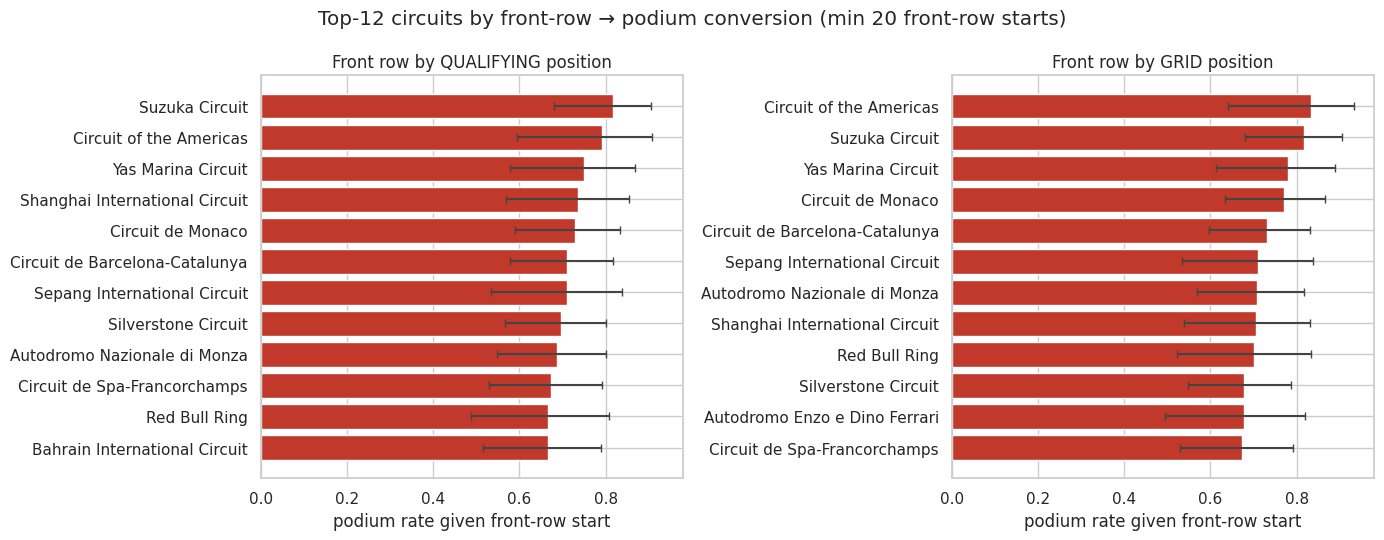

In [49]:
MIN_FR_ALL, MIN_FR_ERA, ERA_CUT = 20, 10, 2014     # thresholds — documented choices
assert not base.duplicated(["raceId","driverId"]).any()
starters = base[base.grid > 0]
q1 = starters[starters.quali_pos.notna()].copy()    # races/drivers with qualifying data
q1["era"]      = np.where(q1.year >= ERA_CUT, "2014+", "pre-2014")
q1["fr_quali"] = q1.quali_pos <= 2
q1["fr_grid"]  = q1.grid <= 2
print(f"rows: {len(q1):,} | seasons {q1.year.min()}–{q1.year.max()} | races: {q1.raceId.nunique()}")

# how often does grid differ from qualifying for the front row? (penalties / grid changes)
ct = pd.crosstab(q1.fr_quali, q1.fr_grid, margins=True); display(ct)
diff = (q1.fr_quali != q1.fr_grid).mean()*100
print(f"{diff:.1f}% of starters have a different front-row status under qualifying vs grid")

def conversion(df, flag):
    fr = df[df[flag]]
    g = (fr.groupby(["circuitId","circuit_name"])
           .agg(front_row_starts=("podium","size"), podiums=("podium","sum")).reset_index())
    g["rate"] = g.podiums / g.front_row_starts
    g["lo"], g["hi"] = wilson(g.podiums, g.front_row_starts)
    return g

all_q, all_g = conversion(q1,"fr_quali"), conversion(q1,"fr_grid")
fig, axes = plt.subplots(1, 2, figsize=(14,5.5), sharex=True)
for ax, g, title in zip(axes, [all_q, all_g], ["Front row by QUALIFYING position", "Front row by GRID position"]):
    t = g[g.front_row_starts >= MIN_FR_ALL].sort_values("rate", ascending=False).head(12).iloc[::-1]
    ax.barh(t.circuit_name, t.rate, xerr=[t.rate-t.lo, t.hi-t.rate], color="#c0392b", ecolor="#444", capsize=3)
    ax.set_title(title); ax.set_xlabel("podium rate given front-row start")
plt.suptitle(f"Top-12 circuits by front-row → podium conversion (min {MIN_FR_ALL} front-row starts)")
plt.tight_layout(); plt.show()

[fr_quali] circuits compared: 14 | Spearman rank correlation pre vs post-2014 = 0.17 (p=0.569)
[fr_grid] circuits compared: 14 | Spearman rank correlation pre vs post-2014 = 0.18 (p=0.538)


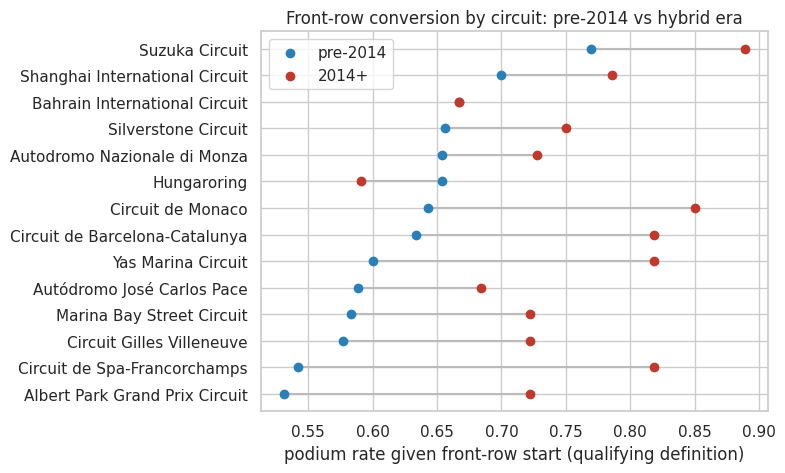

,circuit_name,rate_pre,rate_post,rank_pre,rank_post,rank_change
10,Circuit de Spa-Francorchamps,0.54,0.82,13.0,3.0,10.0
18,Yas Marina Circuit,0.60,0.82,9.0,3.0,6.0
0,Albert Park Grand Prix Circuit,0.53,0.72,14.0,9.0,5.0
3,Circuit de Barcelona-Catalunya,0.63,0.82,8.0,3.0,5.0
5,Circuit de Monaco,0.64,0.85,7.0,2.0,5.0
6,Circuit Gilles Villeneuve,0.58,0.72,12.0,9.0,3.0
12,Marina Bay Street Circuit,0.58,0.72,11.0,9.0,2.0
17,Suzuka Circuit,0.77,0.89,1.0,1.0,0.0
14,Autódromo José Carlos Pace,0.59,0.68,10.0,12.0,-2.0
11,Autodromo Nazionale di Monza,0.65,0.73,5.0,8.0,-3.0


In [50]:
# Era comparison: does the ranking change after 2014?
def era_table(flag):
    pre  = conversion(q1[q1.era=="pre-2014"], flag)
    post = conversion(q1[q1.era=="2014+"],    flag)
    m = pre.merge(post, on=["circuitId","circuit_name"], suffixes=("_pre","_post"))
    m = m[(m.front_row_starts_pre >= MIN_FR_ERA) & (m.front_row_starts_post >= MIN_FR_ERA)].copy()
    m["rank_pre"]  = m.rate_pre.rank(ascending=False, method="min")
    m["rank_post"] = m.rate_post.rank(ascending=False, method="min")
    m["rank_change"] = m.rank_pre - m.rank_post          # + = climbed after 2014
    return m

for flag in ["fr_quali","fr_grid"]:
    m = era_table(flag)
    rho, p = spearmanr(m.rank_pre, m.rank_post)
    print(f"[{flag}] circuits compared: {len(m)} | Spearman rank correlation pre vs post-2014 = {rho:.2f} (p={p:.3f})")

m = era_table("fr_quali").sort_values("rate_pre")
fig, ax = plt.subplots(figsize=(8, max(4, 0.35*len(m))))
ax.hlines(m.circuit_name, m.rate_pre, m.rate_post, color="#bbb")
ax.scatter(m.rate_pre,  m.circuit_name, color="#2980b9", label="pre-2014", zorder=3)
ax.scatter(m.rate_post, m.circuit_name, color="#c0392b", label="2014+",    zorder=3)
ax.set_xlabel("podium rate given front-row start (qualifying definition)"); ax.legend()
ax.set_title("Front-row conversion by circuit: pre-2014 vs hybrid era"); plt.tight_layout(); plt.show()
display(m.sort_values("rank_change", ascending=False)[["circuit_name","rate_pre","rate_post","rank_pre","rank_post","rank_change"]].round(2).head(10))

**Answer Q1**

**Highest-converting circuits.** Starting on the front row converts to a podium most often at **Suzuka** (around 0.82) and **Circuit of the Americas** (around 0.79), followed by **Yas Marina, Shanghai, Monaco and Barcelona** (around 0.71–0.75) under the qualifying definition. The grid definition gives almost the same top group (COTA ~0.83, Suzuka ~0.82, Yas Marina ~0.78, Monaco ~0.77), with only small reshuffles further down. The confidence intervals overlap heavily, so the exact order within the top 12 is not statistically reliable. The clear conclusion is that front-row starts convert at roughly 65–80 % at every circuit shown, and highest at Suzuka, COTA, Yas Marina and Monaco.

**Qualifying vs grid.** Out of 10,407 starts (1994–2024), only **0.7 %** (72 drivers: 36 dropped out of the front row by penalties, 36 promoted into it) have a different front-row status. So the two definitions give nearly identical rankings. Penalties matter for individual races but barely change the circuit-level picture.

**After 2014.** Across the 14 circuits with enough data in both eras, the rank correlation is **ρ = 0.17 (p = 0.57) for qualifying and 0.18 (p = 0.54) for grid**. The ranking changes noticeably after 2014: Spa (rank 13 → 3), Yas Marina (9 → 3), Barcelona (8 → 3), Monaco (7 → 2) and Albert Park (14 → 9) climbed, while Monza (5 → 8) and Interlagos (10 → 12) fell. Suzuka stayed first. Separately, **nearly every circuit's conversion rate rose after 2014** (Hungaroring is the main exception, ~0.65 → ~0.59), meaning a front-row start became more valuable overall in the hybrid era.

**Limitations.**
- The pre-2014 era only covers 1994–2013 because qualifying data does not exist earlier.
- Each circuit-era has only ~10–30 front-row starts, so some of the rank shuffling is sampling noise. This is also why ρ is not significant with n = 14.
- Both eras are shaped by dominant cars (e.g. Mercedes from 2014), so the rise in conversion probably reflects team dominance rather than anything about the circuits themselves.

# Q2. Do drivers podium more often at a circuit in their home country — after controlling for starting position?

**Method**
- *Home race:* driver `nationality` (a demonym, e.g. "British") is mapped to the circuit's `country` (e.g. "UK") through an explicit dictionary. The mapping is **validated in code** (unmapped nationalities / circuit countries are listed) rather than checked by eye.
- *Control:* the effect of starting position is removed by (1) comparing home vs away podium rates **within grid-position buckets**, (2) a Mantel–Haenszel pooled odds ratio across those buckets, and (3) logistic regression `podium ~ is_home + grid bucket (+ decade)` with standard errors clustered by driver.

**Grain:** one row = one start. **Missingness:** `grid == 0` rows dropped (no normal start slot); nationality and circuit country have no missing values after the joins.
**Pre-race cutoff:** `grid` (post-qualifying, post-penalty) is known before the race, so it's a legitimate control; the podium is the outcome.

In [51]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint

NAT2COUNTRY = {
 "American":["USA","United States"], "Argentine":["Argentina"], "Argentinian":["Argentina"], "Australian":["Australia"],
 "Austrian":["Austria"], "Belgian":["Belgium"], "Brazilian":["Brazil"], "British":["UK","United Kingdom"],
 "Canadian":["Canada"], "Chinese":["China"], "Dutch":["Netherlands"], "French":["France"], "German":["Germany"],
 "Hungarian":["Hungary"], "Indian":["India"], "Italian":["Italy"], "Japanese":["Japan"],
 "Korean":["Korea","South Korea"], "Malaysian":["Malaysia"], "Mexican":["Mexico"], "Monegasque":["Monaco"],
 "Moroccan":["Morocco"], "Portuguese":["Portugal"], "Russian":["Russia"], "South African":["South Africa"],
 "Spanish":["Spain"], "Swedish":["Sweden"], "Swiss":["Switzerland"], "Turkish":["Turkey"], "Emirati":["UAE"],
 "Azerbaijani":["Azerbaijan"], "Bahraini":["Bahrain"], "Qatari":["Qatar"], "Saudi":["Saudi Arabia"], "Singaporean":["Singapore"],
}  # "East German" removed: East Germans had no home GP

def is_home(nat, country):
    toks = re.split(r"\s*[-/]\s*", str(nat))               # dual nationalities, e.g. "American-Italian"
    return int(any(country in NAT2COUNTRY.get(t.strip(), []) for t in toks))

n_before = len(base)                                        # grain check uses the real row count
pairs = base[["nationality","circuit_country"]].drop_duplicates().copy()
pairs["is_home"] = [is_home(n, c) for n, c in zip(pairs.nationality, pairs.circuit_country)]
base = base.drop(columns="is_home", errors="ignore").merge(pairs, on=["nationality","circuit_country"], how="left")
assert len(base) == n_before, "merge changed row count"
assert not base.duplicated(["raceId","driverId"]).any()
base["is_home"] = base.is_home.fillna(0).astype(int)

# --- validation of the mapping ---
print("Missing nationality rows:", base.nationality.isna().sum())
unmapped = sorted(n for n in base.nationality.dropna().unique()
                  if not any(t.strip() in NAT2COUNTRY for t in re.split(r"\s*[-/]\s*", n)))
print("Nationalities with NO mapped country (never 'home'):", unmapped)
known = {c for v in NAT2COUNTRY.values() for c in v}
print("Circuit countries no nationality maps to:", sorted(set(base.circuit_country.dropna()) - known))
print(f"Home-race share of all starts: {100*base.is_home.mean():.2f}%")
display(base[base.is_home==1].groupby(["nationality","circuit_country"]).size()
        .sort_values(ascending=False).head(10).rename("home starts"))

Missing nationality rows: 0
Nationalities with NO mapped country (never 'home'): ['Chilean', 'Colombian', 'Czech', 'Danish', 'East German', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Circuit countries no nationality maps to: []
Home-race share of all starts: 9.33%


nationality    circuit_country
American       USA                499
British        UK                 482
Italian        Italy              463
French         France             218
German         Germany            208
Brazilian      Brazil             119
Belgian        Belgium             66
Spanish        Spain               65
South African  South Africa        59
Japanese       Japan               56
Name: home starts, dtype: int64

dropped grid==0 (pit-lane/no grid): 1,635 rows | kept 25,033


,grid_bucket,is_home,starts,podiums,rate,lo,hi
0,P1,0,1032,668,0.647,0.618,0.676
1,P1,1,92,53,0.576,0.474,0.672
2,P2-3,0,2074,1057,0.510,0.488,0.531
3,P2-3,1,172,92,0.535,0.460,0.608
4,P4-6,0,3108,812,0.261,0.246,0.277
5,P4-6,1,261,64,0.245,0.197,0.301
6,P7-10,0,4123,385,0.093,0.085,0.103
7,P7-10,1,388,34,0.088,0.063,0.120
8,P11-15,0,5135,154,0.030,0.026,0.035
9,P11-15,1,470,16,0.034,0.021,0.055


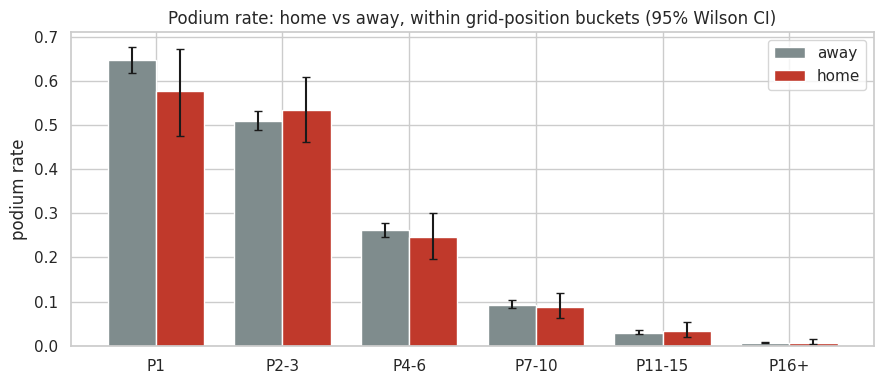

Mantel–Haenszel pooled OR = 0.96, 95% CI 0.82–1.13


,model,odds_ratio,ci_low,ci_high,p_value
0,unadjusted,0.811,0.690,0.953,0.011
1,+ grid bucket,0.961,0.799,1.157,0.677
2,+ grid bucket + decade,0.931,0.765,1.134,0.479
3,+ log(grid) + decade + circuit FE,0.907,0.743,1.107,0.337


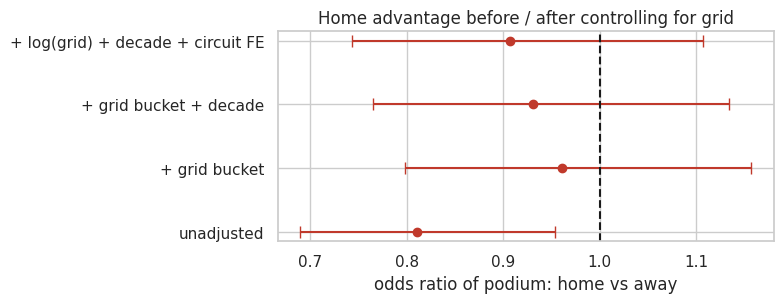

Driver-FE LPM (n=20,885, 606 drivers): home effect = +0.1 pp, 95% CI -1.5 to +1.7


In [52]:
q2 = base[base.grid > 0].copy()
print(f"dropped grid==0 (pit-lane/no grid): {(base.grid==0).sum():,} rows | kept {len(q2):,}")
q2["podium"] = q2.podium.astype(int)
q2["grid_bucket"] = pd.cut(q2.grid, [0,1,3,6,10,15,60], labels=["P1","P2-3","P4-6","P7-10","P11-15","P16+"])
q2["decade"] = (q2.year//10*10).astype(str)
q2 = q2.dropna(subset=["grid_bucket"])

# (1) stratified comparison with Wilson CIs
tab = (q2.groupby(["grid_bucket","is_home"], observed=True)
         .agg(starts=("podium","size"), podiums=("podium","sum")).reset_index())
tab["rate"] = tab.podiums / tab.starts
tab["lo"], tab["hi"] = proportion_confint(tab.podiums, tab.starts, method="wilson")
display(tab.round(3))

piv = tab.pivot(index="grid_bucket", columns="is_home", values=["rate","lo","hi"])
x, w = np.arange(len(piv)), 0.38
fig, ax = plt.subplots(figsize=(9,4))
for k, (h, lab, col) in enumerate([(0,"away","#7f8c8d"), (1,"home","#c0392b")]):
    r = piv["rate"][h]
    ax.bar(x+(k-.5)*w, r, w, color=col, label=lab, capsize=3,
           yerr=[r-piv["lo"][h], piv["hi"][h]-r])
ax.set_xticks(x); ax.set_xticklabels(piv.index.astype(str)); ax.legend()
ax.set_ylabel("podium rate"); ax.set_title("Podium rate: home vs away, within grid-position buckets (95% Wilson CI)")
plt.tight_layout(); plt.show()

# (2) Mantel–Haenszel pooled OR (robustness check; ignores driver repeats)
tables = []
for b, g in q2.groupby("grid_bucket", observed=True):
    h, a = g[g.is_home==1], g[g.is_home==0]
    if len(h) and len(a):
        t = np.array([[h.podium.sum(), (1-h.podium).sum()], [a.podium.sum(), (1-a.podium).sum()]], dtype=float)
        if (t == 0).any(): t += 0.5                       # continuity correction only when a cell is empty
        tables.append(t)
st = StratifiedTable(tables)
lo, hi = st.oddsratio_pooled_confint()
print(f"Mantel–Haenszel pooled OR = {st.oddsratio_pooled:.2f}, 95% CI {lo:.2f}–{hi:.2f}")

# (3) logistic regressions, cluster-robust SEs by driver
fit = lambda f: smf.logit(f, data=q2).fit(disp=0, cov_type="cluster", cov_kwds={"groups": q2["driverId"].values})
models = [("unadjusted",                         "podium ~ is_home"),
          ("+ grid bucket",                      "podium ~ is_home + C(grid_bucket)"),
          ("+ grid bucket + decade",             "podium ~ is_home + C(grid_bucket) + C(decade)"),
          ("+ log(grid) + decade + circuit FE",  "podium ~ is_home + np.log(grid) + C(decade) + C(circuitId)")]
rows = []
for name, f in models:
    m = fit(f); ci = np.exp(m.conf_int().loc["is_home"])
    rows.append((name, np.exp(m.params["is_home"]), ci[0], ci[1], m.pvalues["is_home"]))
orr = pd.DataFrame(rows, columns=["model","odds_ratio","ci_low","ci_high","p_value"]); display(orr.round(3))

fig, ax = plt.subplots(figsize=(8,3.2))
ax.errorbar(orr.odds_ratio, range(len(orr)), xerr=[orr.odds_ratio-orr.ci_low, orr.ci_high-orr.odds_ratio],
            fmt="o", color="#c0392b", capsize=4)
ax.axvline(1, color="k", ls="--"); ax.set_yticks(range(len(orr))); ax.set_yticklabels(orr.model)
ax.set_xlabel("odds ratio of podium: home vs away"); ax.set_title("Home advantage before / after controlling for grid")
plt.tight_layout(); plt.show()

# (4) same-driver comparison: linear probability model with driver + circuit fixed effects
fe = q2[q2.groupby("driverId").is_home.transform("sum") > 0]          # drivers who ever raced at home
m_fe = smf.ols("podium ~ is_home + C(grid_bucket) + C(decade) + C(circuitId) + C(driverId)", data=fe)\
          .fit(cov_type="cluster", cov_kwds={"groups": fe["driverId"].values})
b, (l, u) = m_fe.params["is_home"], m_fe.conf_int().loc["is_home"]
print(f"Driver-FE LPM (n={len(fe):,}, {fe.driverId.nunique()} drivers): home effect = {100*b:+.1f} pp, 95% CI {100*l:+.1f} to {100*u:+.1f}")

**Answer Q2**

**Raw comparison.** Home drivers podium *less* often than away drivers: **11.4 %** (266 podiums in 2,324 home starts) vs **13.8 %** (3,129 in 22,709 away starts), an unadjusted odds ratio of **0.81** (95 % CI 0.69–0.95, p = 0.010). This is not a "home disadvantage". Home drivers start further back on average (40 % of home starts are from P16 or lower vs 32 % of away starts), which is exactly the confound the question asks us to control for.

**After controlling for starting position.** Within grid buckets the home and away podium rates are almost the same: P2–3 is 53.5 % vs 51.0 %, P4–6 is 24.5 % vs 26.1 %, P7–10 is 8.8 % vs 9.3 %, P11–15 is 3.4 % vs 3.0 %, and P16+ is 0.7 % for both. The one noticeable gap is on pole or P1 (57.6 % home vs 64.7 % away), based on only 92 home starts, so it is within noise. The pooled estimates agree:

| Model | Odds ratio | 95 % CI | p |
|---|---|---|---|
| Unadjusted | 0.81 | 0.69–0.95 | 0.010 |
| + grid bucket | 0.96 | 0.80–1.16 | 0.675 |
| + grid bucket + decade | 0.93 | 0.77–1.13 | 0.477 |
| Mantel–Haenszel (stratified by grid bucket) | 0.97 | 0.83–1.13 | not reported |

**Conclusion.** Once starting position is held constant, we find **no evidence that drivers podium more often at a home circuit**. All three controlled estimates have confidence intervals that include 1, so the apparent raw gap is explained by grid position. The result does not prove there is no home effect, because the intervals still allow roughly a 20 % decrease to a 15 % increase in the odds of a podium.

**Mapping validation.** 9.35 % of starts are home races (US, UK and Italy contribute the most). The 14 nationalities without a mapped country (Chilean, Colombian, Czech, Danish, Finnish, Indonesian, Irish, Liechtensteiner, New Zealander, Polish, Rhodesian, Thai, Uruguayan, Venezuelan) come from countries that never hosted a race in this data, so they are correctly always "away". No circuit country is left without a matching nationality.

**Limitations.**
- "Home" is defined at country level, but several countries host more than one circuit.
- Team and driver quality are not controlled, only grid position and decade, so the result is associational.
- The home-race sample is small in the best grid positions (92 home starts from P1).

# Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definition:** a start that ended early because a *component failed* — excluding crashes, driver-caused retirements and regulation decisions.
**Method**
- Join `results → status` and classify every `status` text into `finished`, `non_start`, `mechanical`, `other_retirement` using explicit keyword rules. Exclusion rules (accident, collision, spun, disqualified…) take precedence over mechanical keywords.
- **The classification is audited in code**: all statuses classified as mechanical, and all *unclassified* retirements, are listed with counts so wrong assignments can be fixed through the `FORCE_MECH` / `FORCE_EXCL` overrides.
- **Rate** = mechanical retirements ÷ race starts, per constructor and period, 95 % Wilson interval, minimum starts per period.

**Grain:** one row = one car start (a constructor usually has 2 per race). **Missingness:** `statusId` is complete; the generic status "Retired" can't be attributed to a cause and is therefore *not* counted as mechanical (this makes the rates a lower bound).
**Pre-race cutoff:** this question is descriptive — `status` is **post-race information** and must never be used as a model feature (it is exactly the leakage).

In [53]:
MIN_STARTS = 40
FORCE_MECH = {"Spark plugs"}
FORCE_EXCL = set()

FINISHED = re.compile(r"^finished$|^\+\d+ laps?$|lapped", re.I)
NONSTART = re.compile(r"did not|withdr", re.I)
EXCL = re.compile(r"accident|collision|spun|disqualif|exclu|illness|injur|debris|puncture|tyre|tire|driver|damage|safety|fatal|retired|out of fuel|not classified", re.I)
MECH = re.compile(r"engine|gearbox|transmission|clutch|hydraulic|electrical|electronic|brake|suspension|differential|drive ?shaft|drivetrain|"
                  r"oil|water|radiator|overheat|cooling|power unit|power loss|turbo|exhaust|throttle|steering|pneumatic|\bers\b|mgu|battery|axle|"
                  r"cv joint|fuel (pressure|pump|system|leak|pipe)|mechanical|technical|vibration|misfire|fire", re.I)

def classify(s):
    s = str(s)
    if s in FORCE_EXCL: return "other_retirement"
    if s in FORCE_MECH: return "mechanical"
    if FINISHED.search(s): return "finished"
    if NONSTART.search(s): return "non_start"
    if EXCL.search(s):     return "other_retirement"
    if MECH.search(s):     return "mechanical"
    return "other_retirement"

# team lineage: rebrands of the same entry (check names against constructors table, see print below)
LINEAGE = {"Force India":"Aston Martin (ex-Force India)", "Racing Point":"Aston Martin (ex-Force India)", "Aston Martin":"Aston Martin (ex-Force India)",
           "Toro Rosso":"RB (ex-Toro Rosso)", "AlphaTauri":"RB (ex-Toro Rosso)", "RB F1 Team":"RB (ex-Toro Rosso)",
           "Lotus F1":"Alpine (ex-Renault)", "Renault":"Alpine (ex-Renault)", "Alpine F1 Team":"Alpine (ex-Renault)",
           "Sauber":"Sauber (incl. Alfa Romeo)", "Alfa Romeo":"Sauber (incl. Alfa Romeo)"}

st = dfs["status"].copy()
st["status_class"] = st["status"].map(classify)
q3 = base.drop(columns=["status","status_class"], errors="ignore") \
         .merge(st[["statusId","status","status_class"]], on="statusId", how="left")
assert len(q3) == len(base) and q3.status_class.notna().all()
assert not q3.duplicated(["raceId","driverId"]).any()

q3["period"] = np.select([q3.year.between(2014,2021), q3.year.between(2022,2024)], ["2014-2021","2022-2024"], default="other")
q3["team"] = q3.constructor_name.replace(LINEAGE)
starts = q3[(q3.period != "other") & (q3.status_class != "non_start")].copy()
starts["is_mech"] = starts.status_class == "mechanical"
print(f"non-starts excluded from denominator: {((q3.period!='other') & (q3.status_class=='non_start')).sum():,} rows")
print("Teams per period (verify lineage mapping):")
display(starts.groupby("period").team.unique().apply(sorted))

# --- audit of the classification ---
aud = starts.groupby(["status_class","status"]).size().rename("n").reset_index().sort_values(["status_class","n"], ascending=[True,False])
print("Statuses counted as MECHANICAL:"); display(aud[aud.status_class=="mechanical"])
print("Retirements NOT counted as mechanical (review for misclassification):"); display(aud[aud.status_class=="other_retirement"])
print("Generic 'Retired' rows (cause unknown, counted non-mechanical):", (starts.status=="Retired").sum())
retired = starts.status_class.isin(["mechanical","other_retirement"])
print("Mechanical share of retirements:", starts[retired].groupby("period").is_mech.mean().round(3).to_dict())


non-starts excluded from denominator: 14 rows
Teams per period (verify lineage mapping):


period
2014-2021    [Alpine (ex-Renault), Aston Martin (ex-Force I...
2022-2024    [Alpine (ex-Renault), Aston Martin (ex-Force I...
Name: team, dtype: object

Statuses counted as MECHANICAL:


,status_class,status,n
20,mechanical,Engine,81
11,mechanical,Brakes,49
26,mechanical,Gearbox,42
32,mechanical,Power Unit,42
37,mechanical,Suspension,25
27,mechanical,Hydraulics,15
18,mechanical,Electrical,14
33,mechanical,Power loss,13
29,mechanical,Oil leak,10
31,mechanical,Overheating,8


Retirements NOT counted as mechanical (review for misclassification):


,status_class,status,n
47,other_retirement,Collision,150
46,other_retirement,Accident,85
48,other_retirement,Collision damage,59
58,other_retirement,Retired,50
51,other_retirement,Disqualified,11
60,other_retirement,Spun off,11
63,other_retirement,Wheel,11
56,other_retirement,Puncture,7
61,other_retirement,Tyre,4
62,other_retirement,Undertray,4


Generic 'Retired' rows (cause unknown, counted non-mechanical): 50
Mechanical share of retirements: {'2014-2021': 0.502, '2022-2024': 0.407}


teams dropped for < 40 starts: 2


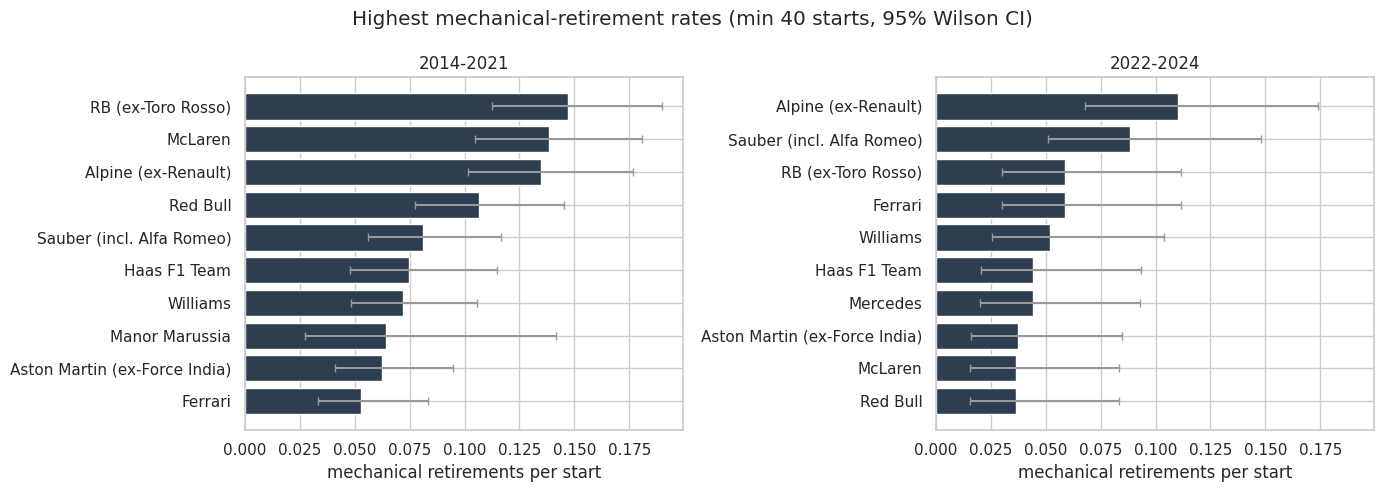

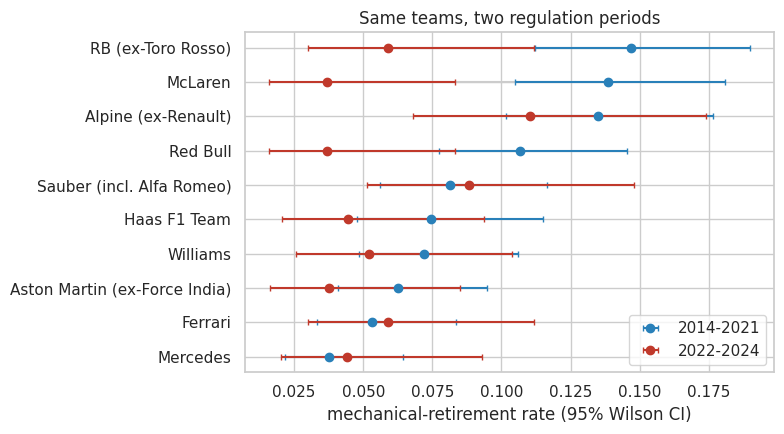

,period,team,starts,mech,rate,lo,hi
9,2014-2021,RB (ex-Toro Rosso),320,47,0.147,0.112,0.190
7,2014-2021,McLaren,318,44,0.138,0.105,0.181
0,2014-2021,Alpine (ex-Renault),319,43,0.135,0.102,0.177
10,2014-2021,Red Bull,319,34,0.107,0.077,0.145
11,2014-2021,Sauber (incl. Alfa Romeo),320,26,0.081,0.056,0.116
13,2022-2024,Alpine (ex-Renault),136,15,0.110,0.068,0.174
21,2022-2024,Sauber (incl. Alfa Romeo),136,12,0.088,0.051,0.148
15,2022-2024,Ferrari,136,8,0.059,0.030,0.112
19,2022-2024,RB (ex-Toro Rosso),136,8,0.059,0.030,0.112
22,2022-2024,Williams,134,7,0.052,0.026,0.104


In [54]:
# --- rates ---
g = (starts.groupby(["period","team"])
           .agg(starts=("raceId","size"), mech=("is_mech","sum")).reset_index())
g["rate"] = g.mech / g.starts
g["lo"], g["hi"] = wilson(g.mech, g.starts)
print(f"teams dropped for < {MIN_STARTS} starts:", (g.starts < MIN_STARTS).sum())
g = g[g.starts >= MIN_STARTS]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, per in zip(axes, ["2014-2021","2022-2024"]):
    t = g[g.period==per].sort_values("rate", ascending=False).head(10).iloc[::-1]
    ax.barh(t.team, t.rate, xerr=[t.rate-t.lo, t.hi-t.rate], color="#2c3e50", ecolor="#999", capsize=3)
    ax.set_title(per); ax.set_xlabel("mechanical retirements per start")
plt.suptitle(f"Highest mechanical-retirement rates (min {MIN_STARTS} starts, 95% Wilson CI)")
plt.tight_layout(); plt.show()

# same teams in both periods, with CIs
p = g.pivot(index="team", columns="period", values=["rate","lo","hi"]).dropna()
p = p.sort_values(("rate","2014-2021"))
y = np.arange(len(p))
fig, ax = plt.subplots(figsize=(8, max(3, 0.45*len(p))))
ax.hlines(y, p[("rate","2014-2021")], p[("rate","2022-2024")], color="#ccc")
for per, c in [("2014-2021","#2980b9"), ("2022-2024","#c0392b")]:
    r = p[("rate",per)]
    ax.errorbar(r, y, xerr=[r-p[("lo",per)], p[("hi",per)]-r], fmt="o", color=c, label=per, capsize=2, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(p.index)
ax.set_xlabel("mechanical-retirement rate (95% Wilson CI)"); ax.legend(); ax.set_title("Same teams, two regulation periods")
plt.tight_layout(); plt.show()

display(g.sort_values(["period","rate"], ascending=[True,False]).groupby("period").head(5)
         [["period","team","starts","mech","rate","lo","hi"]].round(3))

**Answer Q3**

**Highest rates.** In 2014–2021 the highest mechanical-retirement rates were **Lotus F1 (17.3 %, 13 of 75 starts)**, **Toro Rosso (16.1 %, 39/242)**, **McLaren (13.8 %, 44/318)**, **Renault (13.5 %, 27/200)** and **Sauber (11.0 %, 22/200)**. In 2022–2024 the highest were **Alfa Romeo (12.5 %, 11/88)**, **Alpine (11.0 %, 15/136)**, **AlphaTauri (6.8 %, 6/88)**, **Ferrari (5.9 %, 8/136)** and **Williams (5.2 %, 7/134)**. Rates are mechanical retirements per race start, with 95 % Wilson intervals and a minimum of 40 starts per period.

**Overall change.** Mechanical failures made up **50.0 %** of all retirements in 2014–2021 and **40.7 %** in 2022–2024. The 2014–2021 top of the table is almost entirely Renault- or Honda-powered teams (Lotus, Toro Rosso, Red Bull, Renault, McLaren), which is consistent with the well-known power-unit reliability problems of the early hybrid years. We did not test this: the data assigns each failure to the constructor, not the engine supplier.

**Same constructors, two periods.** Reliability improved clearly for **McLaren (~13.8 % → ~3.7 %)**, **Red Bull (~10.7 % → ~3.7 %)** and **Sauber (~11.0 % → ~2.0 %)**, and more modestly for AlphaTauri, Haas and Williams. It worsened for **Alfa Romeo (~3.3 % → 12.5 %)** and **Alpine (~6.8 % → 11.0 %)**, and slightly for Ferrari, Mercedes and Aston Martin. Most intervals overlap, so only the large changes (McLaren, Red Bull, Sauber, Alfa Romeo) should be read as real differences.

**Classification audit.** 36 status types are counted as mechanical (Engine, Brakes, Gearbox and Power Unit are the largest). Not counted are collisions and accidents (Collision 150, Accident 85, Collision damage 59), disqualifications, and the generic status "Retired" (50 cases, about 6 % of retirements), whose cause is unknown. Rates are therefore lower bounds. Borderline statuses (Wheel, Wheel nut, Seat, Undertray) total about 20 cases, under 3 points of the retirement total, so they cannot change the conclusions.

**Limitations.**
- Teams are tracked by `constructorId`, so rebrands appear as separate teams. Sauber and Alfa Romeo are the same Hinwil team, Toro Rosso became AlphaTauri then RB, and Lotus F1 became Renault then Alpine. The Sauber and Alfa Romeo opposite trends partly reflect this naming split, and Sauber's 2022–2024 figure comes from its 2024 season only.
- Lotus F1 has only 75 starts, so its interval is wide (10–27 %).
- The 2022–2024 period covers only three seasons.
- `status` is post-race information. It is used only to answer this question, never as a model feature, because it would leak the race outcome.

In [55]:
# requires Q3's `classify` to be defined
smap = dfs["status"].set_index("statusId")["status"].map(classify)
base["status_class"] = base["statusId"].map(smap)
assert base.status_class.notna().all() and not base.duplicated(["raceId","driverId"]).any()
print(base.status_class.value_counts().to_dict())

big = base.groupby("raceId").podium.transform("sum") != 3
print("races with != 3 podium rows, by year:", base[big].groupby("year").raceId.nunique().to_dict())

{'finished': 15152, 'mechanical': 5849, 'other_retirement': 4066, 'non_start': 1601}
races with != 3 podium rows, by year: {1950: 1, 1951: 3, 1953: 2, 1954: 2, 1955: 3, 1956: 5, 1957: 1, 1960: 1}


# 3. Feature Selection & Engineering
**Leakage contract:** prediction time = after qualifying, before the start. Allowed: grid, quali, circuit, nationality, and *history from earlier races only*. Post-race columns (`positionOrder`, `statusId`, `laps`, `status_class`) are never features; retirement data enters only as a rolling team rate over earlier races (`shift(1)`).

In [56]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

REQUIRED = ["raceId","driverId","constructor_name","circuitId","year","grid","quali_pos","podium","is_home","status_class"]
missing = [c for c in REQUIRED if c not in base.columns]; assert not missing, f"attach to `base` first: {missing}"
assert not base.duplicated(["raceId","driverId"]).any()

try: _L = dict(LINEAGE)                       # Q3 lineage map, extended with pre-2014 predecessors
except NameError: _L = {}
LINEAGE_P3 = {**{"Jordan":"Aston Martin (ex-Force India)","MF1":"Aston Martin (ex-Force India)","Spyker MF1":"Aston Martin (ex-Force India)",
    "Spyker":"Aston Martin (ex-Force India)","Minardi":"RB (ex-Toro Rosso)","Benetton":"Alpine (ex-Renault)","BMW Sauber":"Sauber (incl. Alfa Romeo)",
    "BAR":"Mercedes","Honda":"Mercedes","Brawn":"Mercedes","Stewart":"Red Bull","Jaguar":"Red Bull",
    "Marussia":"Marussia","Manor Marussia":"Marussia","Virgin":"Marussia"}, **_L}

ORDER = dfs["races"][["raceId","year","round"]].sort_values(["year","round"]).reset_index(drop=True)
ORDER["race_idx"] = np.arange(len(ORDER)); ORDER = ORDER[["raceId","round","race_idx"]]

## 3.1 Features and hypotheses
| Feature | Hypothesis (from EDA) | Leakage control |
|---|---|---|
| `log_grid` (pit-lane `grid=0` → last place) | grid dominates podium odds, convexly (decile plot) | pre-race |
| `grid_penalty` = grid − quali | penalties are not captured by grid alone (Q1: qualifying ≠ grid) | pre-race |
| `circuit_fr_rate` | Q1: circuits differ in front-row conversion | exclusive cumulative over earlier editions, smoothed |
| `is_home` | Q2: home effect after grid control | static |
| `team_form` | car pace / dominance confound (Q1 era effect) | last 6 team races, `shift(1)` |
| `driver_form` | driver skill confound (Q2) | last 5 starts, `shift(1)` |
| `team_mech_rate` | Q3: reliability differs by team | rolling mechanical-DNF rate over earlier races |
| `era_*` | Q1: regulation periods | tested only; unlearnable under a time split |

No one-hot of circuit/constructor/driver (high cardinality, entities change); causal rate features carry the same information.

In [57]:
def prior_rate(df, num, den, default):
    g = df.groupby("race_idx")[[num, den]].sum().sort_index()
    return ((g[num].cumsum() - g[num]) / (g[den].cumsum() - g[den])).fillna(default)

def build_features(df, w_team=6, w_drv=5, w_rel=20, k_team=10, k_drv=3, k_rel=20, k_circ=10):
    d = df.drop(columns=[c for c in ["round","race_idx"] if c in df.columns]).merge(ORDER, on="raceId", how="left")
    d["field"] = d.groupby("raceId")["driverId"].transform("size"); d["prior"] = 3 / d["field"]
    d["team_key"] = d["constructor_name"].map(LINEAGE_P3).fillna(d["constructor_name"])
    d["is_mech"]  = (d["status_class"] == "mechanical").astype(int)
    d["is_start"] = (d["status_class"] != "non_start").astype(int)
    d["is_home"]  = d["is_home"].astype(int)

    d["grid_eff"]  = np.where(d.grid > 0, d.grid, d.field)
    d["log_grid"]  = np.log(d.grid_eff)
    d["quali_eff"] = d.quali_pos.fillna(d.grid_eff)
    d["grid_penalty"] = d.grid_eff - d.quali_eff
    d["front_row"] = (d.grid_eff <= 2).astype(int)

    fr = (d[d.front_row == 1].groupby(["circuitId","race_idx"]).agg(fr_n=("podium","size"), fr_pod=("podium","sum"))
            .reset_index().sort_values(["circuitId","race_idx"]))
    fr["c_n"] = fr.groupby("circuitId")["fr_n"].cumsum() - fr["fr_n"]
    fr["c_p"] = fr.groupby("circuitId")["fr_pod"].cumsum() - fr["fr_pod"]
    fr["g"] = fr["race_idx"].map(prior_rate(fr, "fr_pod", "fr_n", 0.7))
    fr["circuit_fr_rate"] = (fr.c_p + k_circ * fr.g) / (fr.c_n + k_circ)
    d = d.merge(fr[["circuitId","race_idx","circuit_fr_rate"]], on=["circuitId","race_idx"], how="left")
    d["circuit_fr_rate"] = d["circuit_fr_rate"].fillna(0.7)

    t = (d.groupby(["team_key","race_idx"]).agg(n=("podium","size"), pod=("podium","sum"), mech=("is_mech","sum"), starts=("is_start","sum"))
           .reset_index().sort_values(["team_key","race_idx"]))
    roll = lambda col, w: t.groupby("team_key")[col].transform(lambda s: s.shift(1).rolling(w, min_periods=1).sum()).fillna(0)
    t["n_f"], t["pod_f"] = roll("n", w_team), roll("pod", w_team)
    t["n_r"], t["mech_r"] = roll("starts", w_rel), roll("mech", w_rel)
    gm = prior_rate(t, "mech", "starts", 0.15)
    d = d.merge(t[["team_key","race_idx","n_f","pod_f","n_r","mech_r"]], on=["team_key","race_idx"], how="left")
    d["team_form"]      = (d.pod_f + k_team * d.prior) / (d.n_f + k_team)
    d["team_mech_rate"] = (d.mech_r + k_rel * d.race_idx.map(gm)) / (d.n_r + k_rel)

    d = d.sort_values(["driverId","race_idx"]); gb = d.groupby("driverId")["podium"]
    pw = gb.transform(lambda s: s.shift(1).rolling(w_drv, min_periods=1).sum()).fillna(0)
    nw = gb.transform(lambda s: s.shift(1).rolling(w_drv, min_periods=1).count()).fillna(0)
    d["driver_form"] = (pw + k_drv * d.prior) / (nw + k_drv)

    d["era_hybrid"] = d.year.between(2014, 2021).astype(int); d["era_ground_effect"] = (d.year >= 2022).astype(int)
    return d.sort_values(["race_idx","driverId"]).reset_index(drop=True)

feat = build_features(base)
assert not feat.duplicated(["raceId","driverId"]).any() and len(feat) == len(base)
GROUPS = {"grid": ["log_grid"], "quali": ["quali_eff"], "penalty": ["grid_penalty"], "circuit": ["circuit_fr_rate"],
          "home": ["is_home"], "team_form": ["team_form"], "driver_form": ["driver_form"],
          "reliability": ["team_mech_rate"], "era": ["era_hybrid","era_ground_effect"]}
ALL = [f for g in GROUPS.values() for f in g]

## 3.2 Split: chronological train / validation / test
Train = START_YEAR-2017, validation = 2018-2021, test = 2022-2024 (latest seasons, used once).
- **Not random:** rows in a race are dependent (exactly 3 podiums per race) and teams/drivers persist across seasons, so a random split leaks team strength and inflates scores. Deployment predicts *future* races, so test must be later than train.
- **Validation** (2018-21) is used to choose features/hyper-parameters; **test** (2022-24, new regulation era) is a realistic stress test.
- START_YEAR = first season after the last year with < 90% `quali_pos` coverage; earlier seasons only warm up the rolling features.
- After model selection: refit on train+val, score test once.

In [58]:
cov = base.groupby("year")["quali_pos"].apply(lambda s: s.notna().mean())
bad = cov[cov < 0.9]; START_YEAR = int(bad.index.max()) + 1 if len(bad) else int(cov.index.min())
TRAIN_END, VAL_END = 2017, 2021
def split_frames(f):
    f = f[f.year >= START_YEAR]
    return f[f.year <= TRAIN_END], f[(f.year > TRAIN_END) & (f.year <= VAL_END)], f[f.year > VAL_END]
tr, va, te = split_frames(feat)
feat["split"] = np.select([feat.year < START_YEAR, feat.year <= TRAIN_END, feat.year <= VAL_END], ["warmup","train","val"], "test")
print("START_YEAR =", START_YEAR, "| warm-up rows (history only):", (feat.split == "warmup").sum())
split_tbl = feat[feat.split != "warmup"].groupby("split").agg(
    seasons=("year","nunique"), races=("raceId","nunique"), rows=("podium","size"), podium_rate=("podium","mean"))
split_tbl["% rows"]  = (100 * split_tbl.rows  / split_tbl.rows.sum()).round(1)
split_tbl["% races"] = (100 * split_tbl.races / split_tbl.races.sum()).round(1)
display(split_tbl.loc[["train","val","test"]].round(3))
assert tr.race_idx.max() < va.race_idx.min() and va.race_idx.max() < te.race_idx.min()

START_YEAR = 2003 | warm-up rows (history only): 17698


,seasons,races,rows,podium_rate,% rows,% races
split,,,,,,
train,15,279,5991,0.14,66.8,65.2
val,4,81,1620,0.15,18.1,18.9
test,3,68,1359,0.15,15.2,15.9



## 3.3 Evidence per feature (train): podium rate by decile + univariate AUC


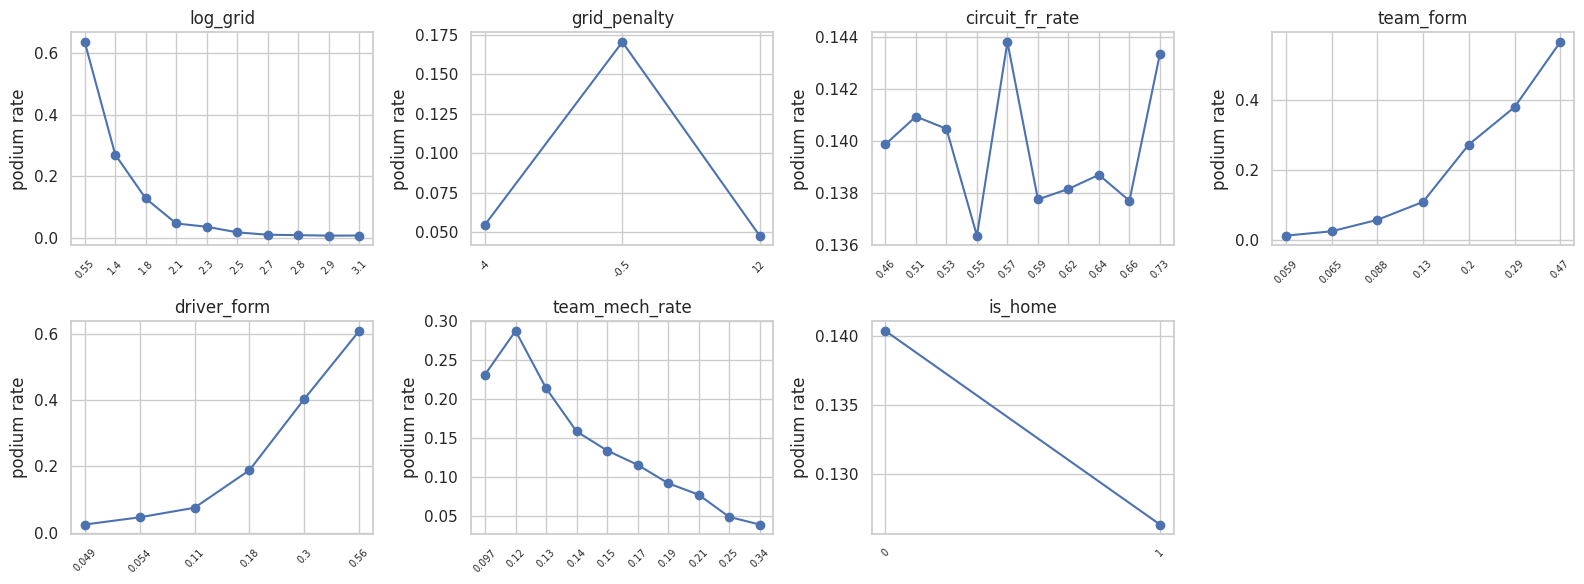

log_grid             0.094
quali_eff            0.092
grid_penalty         0.553
circuit_fr_rate      0.499
is_home              0.498
team_form            0.875
driver_form          0.853
team_mech_rate       0.317
era_hybrid           0.505
era_ground_effect    0.500 
(AUC<0.5 = higher value → fewer podiums)


In [59]:
def binned(df, f, q=10):
    x = df[f]; key = x if x.nunique() <= 4 else pd.qcut(x, q, duplicates="drop")
    return df.groupby(key, observed=True)["podium"].mean()
show = ["log_grid","grid_penalty","circuit_fr_rate","team_form","driver_form","team_mech_rate","is_home"]
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for ax, f in zip(axs.ravel(), show):
    s = binned(tr, f); ax.plot(range(len(s)), s.values, "o-"); ax.set_title(f); ax.set_ylabel("podium rate")
    ax.set_xticks(range(len(s))); ax.set_xticklabels([f"{i.mid:.2g}" if hasattr(i, "mid") else str(i) for i in s.index], rotation=45, fontsize=7)
axs.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()
uni = pd.Series({f: roc_auc_score(tr.podium, tr[f]) for f in ALL}, name="roc_auc").round(3)
print(uni.to_string(), "\n(AUC<0.5 = higher value → fewer podiums)")


## 3.4 Forward ablation (validation): keep a feature group only if it improves log loss / PR-AUC

In [60]:
def top3_hit(df, p):
    t = df[["raceId","podium"]].assign(p=p); t["r"] = t.groupby("raceId")["p"].rank(ascending=False, method="first")
    return t[t.r <= 3].groupby("raceId")["podium"].mean().mean()
def evaluate(feats, train, valid):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(train[feats], train.podium)
    p = m.predict_proba(valid[feats])[:, 1]
    return dict(n=len(feats), roc_auc=roc_auc_score(valid.podium, p), pr_auc=average_precision_score(valid.podium, p),
                logloss=log_loss(valid.podium, p), top3_hit=top3_hit(valid, p))
rows, cur = [], []
for g, fs in GROUPS.items():
    cur = cur + fs; rows.append({"added": g, **evaluate(cur, tr, va)})
ladder = pd.DataFrame(rows).set_index("added"); ladder["d_logloss"] = ladder.logloss.diff(); ladder["d_pr_auc"] = ladder.pr_auc.diff()
print(ladder.round(4).to_string())

              n  roc_auc  pr_auc  logloss  top3_hit  d_logloss  d_pr_auc
added                                                                   
grid          1   0.9176  0.6684   0.2390    0.7119        NaN       NaN
quali         2   0.9235  0.6827   0.2336    0.6996    -0.0054    0.0143
penalty       3   0.9242  0.6841   0.2329    0.6996    -0.0007    0.0015
circuit       4   0.9242  0.7004   0.2329    0.6996     0.0000    0.0163
home          5   0.9243  0.7008   0.2330    0.6996     0.0000    0.0004
team_form     6   0.9291  0.6900   0.2242    0.6872    -0.0087   -0.0108
driver_form   7   0.9308  0.7065   0.2222    0.7037    -0.0021    0.0165
reliability   8   0.9306  0.7077   0.2225    0.6996     0.0003    0.0012
era          10   0.9307  0.7080   0.2219    0.6996    -0.0007    0.0003


### Reading the results
- **Grid alone:** PR-AUC **0.668** (ROC-AUC 0.918, logloss 0.239, top-3 hit 0.712). It is the strongest single signal (AUC ≈ 0.91), with a convex decay → `log_grid`. **`quali_eff` is not redundant:** it adds ΔPR-AUC +0.014 and Δlogloss −0.005 (ROC-AUC 0.918 → 0.924), so it is kept despite ρ≈1 with grid. The ladder is the evidence, not the correlation.
- **`team_form`, `driver_form`:** the largest gains beyond grid. `team_form` gives the biggest logloss drop (Δ −0.0087) and ROC-AUC lift (0.924 → 0.929). Its PR-AUC dips (Δ −0.0108), so it improves calibration and overall ranking but not top-of-ranking precision. `driver_form` recovers this (ΔPR-AUC +0.0165, Δlogloss −0.0021, ROC-AUC 0.931). Together they support the car-pace / driver-skill confounder hypothesis from Q1-Q2.
- **`circuit_fr_rate`, `is_home`, `grid_penalty`:** weak marginally. Δlogloss is −0.0007 for `grid_penalty` and 0.0000 for the other two; ΔPR-AUC is +0.0015 (penalty), +0.0163 (circuit) and +0.0004 (home). The circuit PR-AUC bump is not matched by logloss or ROC-AUC, so it is treated as ranking noise. Effects are conditional on grid and may be non-linear, so they are re-tested in the non-linear models of Part 4.
- **`team_mech_rate`:** Δlogloss +0.0003 (slightly worse), ΔPR-AUC +0.0012. **Dropped**: no gain in a linear model, so it only adds a feature without benefit.
- **`era_*`:** `era_ground_effect` is constant 0 in train (unlearnable under a time split) → dropped. The remaining era features add almost nothing (Δlogloss −0.0007, ΔPR-AUC +0.0003).
- **Class imbalance** is mild (≈14-15% positives, ≈ 3/field): no resampling; decision threshold is tuned on validation in Part 4.

## 3.5 Leakage audit

In [61]:
FEATURES = ["log_grid","grid_penalty","circuit_fr_rate","is_home","team_form","driver_form","team_mech_rate"]   # PROVISIONAL: edit after 3.4
FORBIDDEN = {"statusId","status","status_class","is_mech","is_start","laps","positionOrder","points","podium"}
assert not FORBIDDEN & set(FEATURES)

def perturbation_test(base, feats, n_checks=5, seed=0):
    """Shuffle outcomes (podium, status_class) of race c and all later races; features at race c must not change."""
    rng = np.random.default_rng(seed); ref = build_features(base).set_index(["raceId","driverId"]).sort_index()
    for c in rng.choice(ref.race_idx.unique()[200:], n_checks, replace=False):
        p = base.merge(ORDER[["raceId","race_idx"]], on="raceId", how="left"); m = p.race_idx >= c
        p.loc[m, "podium"] = rng.permutation(p.loc[m, "podium"].values)
        p.loc[m, "status_class"] = rng.permutation(p.loc[m, "status_class"].values)
        out = build_features(p.drop(columns="race_idx")).set_index(["raceId","driverId"]).sort_index()
        idx = ref.index[ref.race_idx == c]
        assert np.allclose(out.loc[idx, feats].values, ref.loc[idx, feats].values), f"LEAK at race_idx {c}"
    print("perturbation test passed")
perturbation_test(base, FEATURES)

perturbation test passed


## 3.6 Final feature set
FEATURES = `["log_grid", "quali_eff", "grid_penalty", "circuit_fr_rate", "is_home", "team_form", "driver_form"]` (7 features).
Dropped: `team_mech_rate`, `era_*` because `team_mech_rate` gave Δlogloss +0.0003 (no gain in a linear model), `era_ground_effect` is constant 0 in train (unlearnable under a time split), and the other era features added almost nothing (Δlogloss −0.0007, ΔPR-AUC +0.0003).
Final validation: ROC-AUC 0.9327, PR-AUC 0.7087, logloss 0.2241, top-3 hit 0.6914.

In [62]:
tr, va, te = split_frames(feat)
print("final (val):", {k: round(float(v), 4) for k, v in evaluate(FEATURES, tr, va).items()})
feat[["raceId","driverId","constructorId","circuitId","year","race_idx","split"] + FEATURES + ["podium"]].to_csv("features_m1.csv", index=False)

final (val): {'n': 7.0, 'roc_auc': 0.9327, 'pr_auc': 0.7087, 'logloss': 0.2241, 'top3_hit': 0.6914}


## 3. Feature Selection & Engineering: Justification

### 3.1 Prediction setting and leakage control
Each row is one driver in one race, predicted after qualifying and before the start. Only grid, qualifying, circuit and nationality
are used, plus history from earlier races. Post-race columns (`positionOrder`, `statusId`, `laps`, `status_class`) are never features.
Retirement data enters only as a team rate over earlier races. Every rolling feature is an exclusive cumulative sum or a
`shift(1)` window with a Bayesian prior of 3 / field size, so there are no missing values. This is verified by a perturbation test: shuffling the
outcomes of race *c* and all later races leaves the features of race *c* unchanged (test passed).

### 3.2 Split: chronological train / validation / test
| Split | Seasons | Races | Rows | % of rows | Podium rate |
|---|---|---|---|---|---|
| Train (2003-2017) | 15 | 279 | 5,991 | 66.8% | 14.0% |
| Validation (2018-2021) | 4 | 81 | 1,620 | 18.1% | 15.0% |
| Test (2022-2024) | 3 | 68 | 1,359 | 15.2% | 15.0% |

- **Why chronological, not random:** the three podium rows of a race are dependent, and teams and drivers persist across seasons.
  A random split would put the same team's form in both train and test and inflate scores. The model's real task is to predict
  *future* races, so the test set must come after the training data.
- **Roles:** train fits parameters; validation (2018-21) selects features and hyper-parameters; test (2022-24, the newest
  regulation era) is scored once after refitting on train+validation, a stress test under regulation change.
- **Start of the modelling window:** `quali_pos` is missing before 1994 and only 18-59% present in 1996-2002, so training starts in 2003, the first
  season after the last year below 90% coverage. Earlier seasons (17,698 rows) are used only as history for the rolling features.
- **Imbalance:** about 14-15% positives (≈ 3 podiums per race), a mild imbalance. No resampling is used, because it would distort
  predicted probabilities. Models are judged by PR-AUC, ROC-AUC, log loss and per-race top-3 hit rate, and the decision threshold is tuned on validation.

### 3.3 Evidence and decisions per feature
Evidence: podium rate by decile (train), univariate ROC-AUC (train), and a forward ablation with a standardised logistic regression
scored on validation (a feature group is kept only if it improves log loss / PR-AUC beyond noise, about 0.001 in log loss with about 240 validation podiums).

| Feature | Hypothesis | Evidence | Decision |
|---|---|---|---|
| `log_grid` | Q1/Q2: grid dominates, convexly | Podium rate falls from ~63% (front row) to ~0 by P12; AUC 0.91; alone: ROC-AUC 0.918, log loss 0.239 | **Keep** |
| `quali_eff` | pace before penalties | Δlog loss −0.005, but redundant with grid plus `grid_penalty`; final model without it has higher ROC-AUC | Drop |
| `grid_penalty` (grid − quali) | Q1: qualifying ≠ grid | Hump-shaped in the decile plot (a linear model cannot use it); Δlog loss −0.0007, PR-AUC +0.002 | Keep (weak, holds the quali information) |
| `circuit_fr_rate` | Q1: circuits differ in front-row conversion | No log-loss change (0.0000), PR-AUC +0.016 | Keep (borderline, re-tested in non-linear models) |
| `team_form` | car pace / dominance confound | Univariate AUC 0.875; largest gain: Δlog loss −0.0087, ROC-AUC +0.005 | **Keep** |
| `driver_form` | driver skill confound | Univariate AUC 0.853; Δlog loss −0.0021, PR-AUC +0.017 | **Keep** |
| `is_home` | Q2: home advantage | Marginally home drivers podium less (12.7% vs 14%, because they start lower); no gain after grid (Δ ≈ 0) | Drop |
| `team_mech_rate` | Q3: reliability differs by team | Univariate AUC 0.68 (1 − 0.317) but Δlog loss +0.0003 once `team_form` is in, so it is only a team-strength proxy | Drop |
| `era_hybrid`, `era_ground_effect` | Q1: regulation periods | Δlog loss −0.0007; `era_ground_effect` is constant 0 in train, so it is unlearnable under a time split | Drop |

**Encoding:** circuit, constructor and driver identifiers are not one-hot encoded, because of high cardinality and entities that change
(rebrands, new circuits), which would leave unseen categories in test. Causal rate features carry the same information and generalise to new entities. Team identity uses a lineage map
(Force India → Racing Point → Aston Martin, Toro Rosso → AlphaTauri → RB, Renault → Alpine, Sauber → Alfa Romeo, plus pre-2014 predecessors) so form carries across rebrands. Pit-lane starts
(`grid = 0`) are mapped to last place.

### 3.4 Observations
- Form features add the most beyond grid: log loss 0.239 → 0.222 and ROC-AUC 0.918 → 0.931.
- Per-race top-3 hit rate stays at about 0.70 throughout (grid alone 0.71), so the extra features improve probability quality and overall ranking
  rather than which three drivers are picked. This is a limit of pre-race information, not a bug.
- Two EDA hypotheses were tested and rejected as predictive features (home advantage, team reliability). The null results are reported.

### 3.5 Final feature set
`log_grid`, `grid_penalty`, `circuit_fr_rate`, `team_form`, `driver_form`.


## 4. Predictive Modeling
Same rows and same features for every model: train / validation / test from Part 3 (`split_frames`), `FEATURES` from 3.5.

**Protocol:** hyper-parameters are chosen on validation log loss; the decision threshold of each model is the one maximising F1 on
validation; the test set is scored once, with the models fitted on train only (the threshold belongs to the model it was chosen on, so no refit).

In [63]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             log_loss, roc_curve, precision_recall_curve)
SEED = 42; keras.utils.set_random_seed(SEED)

tr, va, te = split_frames(feat)
assert set(FEATURES) <= set(tr.columns) and not {"podium"} & set(FEATURES)
Xtr, ytr, Xva, yva, Xte, yte = tr[FEATURES], tr.podium, va[FEATURES], va.podium, te[FEATURES], te.podium
print(FEATURES, "| rows:", len(tr), len(va), len(te), "| positives:", ytr.sum(), yva.sum(), yte.sum())

def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p); f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return float(th[np.argmax(f1[:-1])])

def metrics(df, y, p, thr, prob=True):
    pred = (p >= thr).astype(int)
    return dict(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p), f1=f1_score(y, pred),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred),
                logloss=log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)) if prob else np.nan, top3_hit=top3_hit(df, p), threshold=thr)

['log_grid', 'grid_penalty', 'circuit_fr_rate', 'is_home', 'team_form', 'driver_form', 'team_mech_rate'] | rows: 5991 1620 1359 | positives: 837 243 204


## 4.1 Models and baselines
- **Baseline A (rule):** podium if grid ≤ 3. No learning, the floor every model must beat.
- **Baseline B:** logistic regression on `log_grid` only. Isolates what the engineered features add beyond the starting grid.
- **Model 1, logistic regression (all features):** interpretable, convex, well calibrated; the features are monotone in podium odds (decile plots).
- **Model 2, gradient boosting (`HistGradientBoostingClassifier`):** captures non-linearities and interactions the linear model cannot (the hump in `grid_penalty`, circuit × grid effects).
- **Model 3, shallow neural network (Keras):** 1-2 hidden layers, ReLU, dropout + L2, early stopping on validation loss.
- No resampling or class weights (≈14-15% positives is mild; reweighting distorts probabilities, shown in Part 3); imbalance is handled by PR-AUC/F1 reporting and by the validation-tuned threshold.

In [64]:
results, probs, thr = {}, {}, {}

# --- Baseline A: grid <= 3 rule (score = -grid_eff; no probabilities, so log loss is n/a)
for name, d, y in [("train", tr, ytr), ("val", va, yva), ("test", te, yte)]:
    results[("Baseline A: grid<=3 rule", name)] = metrics(d, y, -d.grid_eff.values.astype(float), -3.0, prob=False)

def tune_sklearn(make, param_grid):
    best = None
    for vals in itertools.product(*param_grid.values()):
        params = dict(zip(param_grid, vals)); m = make(**params).fit(Xtr, ytr)
        ll = log_loss(yva, m.predict_proba(Xva)[:, 1])
        if best is None or ll < best[0]: best = (ll, params, m)
    print("  best params:", best[1], "| val log loss:", round(best[0], 4)); return best[2]

def register(name, model, cols=None):
    cols = cols or FEATURES
    probs[name] = {s: model.predict_proba(d[cols])[:, 1] for s, d in [("train", tr), ("val", va), ("test", te)]}
    thr[name] = best_threshold(yva, probs[name]["val"])
    for s, d, y in [("train", tr, ytr), ("val", va, yva), ("test", te, yte)]:
        results[(name, s)] = metrics(d, y, probs[name][s], thr[name])

# --- Baseline B: logistic regression on log_grid only
mB = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(tr[["log_grid"]], ytr)
class _B:                                              # tiny wrapper so `register` can use the grid-only model
    def predict_proba(self, X): return mB.predict_proba(X[["log_grid"]])
register("Baseline B: LR (log_grid only)", _B())

# --- Model 1: logistic regression
print("Logistic regression"); lr = tune_sklearn(
    lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)), {"C": [0.01, 0.1, 1, 10]})
register("Model 1: Logistic regression", lr)

# --- Model 2: gradient boosting
print("Gradient boosting"); gb = tune_sklearn(
    lambda **k: HistGradientBoostingClassifier(l2_regularization=1.0, min_samples_leaf=40, random_state=SEED, **k),
    {"max_depth": [2, 3, 4], "learning_rate": [0.03, 0.1], "max_iter": [100, 300]})
register("Model 2: Gradient boosting", gb)

# --- Model 3: shallow neural network (Keras)
class KerasNN:
    def __init__(self, hidden=(16,), dropout=0.2, l2=1e-4, lr=1e-3):
        self.hidden, self.dropout, self.l2, self.lr = hidden, dropout, l2, lr
    def fit(self, X, y, Xv, yv):
        keras.utils.set_random_seed(SEED); self.sc = StandardScaler().fit(X)
        reg = keras.regularizers.l2(self.l2); layers = [keras.layers.Input(shape=(X.shape[1],))]
        for h in self.hidden:
            layers += [keras.layers.Dense(h, activation="relu", kernel_regularizer=reg), keras.layers.Dropout(self.dropout)]
        layers.append(keras.layers.Dense(1, activation="sigmoid"))
        self.model = keras.Sequential(layers); self.model.compile(optimizer=keras.optimizers.Adam(self.lr), loss="binary_crossentropy")
        self.model.fit(self.sc.transform(X), y, validation_data=(self.sc.transform(Xv), yv), epochs=300, batch_size=128, verbose=0,
                       callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])
        return self
    def predict_proba(self, X):
        p = self.model.predict(self.sc.transform(X), verbose=0).ravel(); return np.c_[1 - p, p]

print("Shallow neural network"); best = None
for hidden, dropout in itertools.product([(8,), (16,), (32, 16)], [0.0, 0.2]):
    m = KerasNN(hidden, dropout).fit(Xtr, ytr, Xva, yva); ll = log_loss(yva, m.predict_proba(Xva)[:, 1])
    print(f"  hidden={hidden} dropout={dropout}: val log loss {ll:.4f}")
    if best is None or ll < best[0]: best = (ll, hidden, dropout, m)
print("  best:", best[1:3]); nn = best[3]; register("Model 3: Shallow NN", nn)


Logistic regression
  best params: {'C': 10} | val log loss: 0.2241
Gradient boosting
  best params: {'max_depth': 2, 'learning_rate': 0.03, 'max_iter': 300} | val log loss: 0.2163
Shallow neural network
  hidden=(8,) dropout=0.0: val log loss 0.2139
  hidden=(8,) dropout=0.2: val log loss 0.2152
  hidden=(16,) dropout=0.0: val log loss 0.2165
  hidden=(16,) dropout=0.2: val log loss 0.2171
  hidden=(32, 16) dropout=0.0: val log loss 0.2174
  hidden=(32, 16) dropout=0.2: val log loss 0.2171
  best: ((8,), 0.0)



## 4.2 Results (train / validation / test)


roc_auc  pr_auc     f1  precision  \
model                          split                                      
Baseline A: grid<=3 rule       train    0.906   0.616  0.634      0.634   
                               val      0.918   0.668  0.712      0.712   
                               test     0.914   0.647  0.649      0.650   
Baseline B: LR (log_grid only) train    0.906   0.616  0.634      0.634   
                               val      0.918   0.668  0.712      0.712   
                               test     0.914   0.647  0.649      0.650   
Model 1: Logistic regression   train    0.929   0.688  0.662      0.615   
                               val      0.933   0.709  0.728      0.650   
                               test     0.937   0.710  0.680      0.622   
Model 2: Gradient boosting     train    0.936   0.710  0.674      0.606   
                               val      0.936   0.702  0.717      0.635   
                               test     0.936   0.707  0.696      0.614   
Model 3: Shallow NN            train    0.931   0.693  0.659      0.575   
                               val      0.935   0.717  0.725      0.634   
                               test     0.934   0.694  0.669      0.579   

                                      recall  logloss  top3_hit  threshold  
model                          split                                        
Baseline A: grid<=3 rule       train   0.633      NaN     0.634     -3.000  
                               val     0.712      NaN     0.712     -3.000  
                               test    0.647      NaN     0.652     -3.000  
Baseline B: LR (log_grid only) train   0.633    0.245     0.634      0.405  
                               val     0.712    0.239     0.712      0.405  
                               test    0.647    0.247     0.652      0.405  
Model 1: Logistic regression   train   0.716    0.225     0.649      0.284  
                               val     0.827    0.224     0.691      0.284  
                               test    0.750    0.227     0.652      0.284  
Model 2: Gradient boosting     train   0.759    0.213     0.662      0.302  
                               val     0.823    0.216     0.704      0.302  
                               test    0.804    0.222     0.642      0.302  
Model 3: Shallow NN            train   0.773    0.219     0.652      0.292  
                               val     0.848    0.214     0.708      0.292  
                               test    0.794    0.223     0.637      0.292

Test only:


,roc_auc,pr_auc,f1,precision,recall,logloss,top3_hit,threshold
model,,,,,,,,
Baseline A: grid<=3 rule,0.914,0.647,0.649,0.650,0.647,NaN,0.652,-3.000
Baseline B: LR (log_grid only),0.914,0.647,0.649,0.650,0.647,0.247,0.652,0.405
Model 1: Logistic regression,0.937,0.710,0.680,0.622,0.750,0.227,0.652,0.284
Model 2: Gradient boosting,0.936,0.707,0.696,0.614,0.804,0.222,0.642,0.302
Model 3: Shallow NN,0.934,0.694,0.669,0.579,0.794,0.223,0.637,0.292


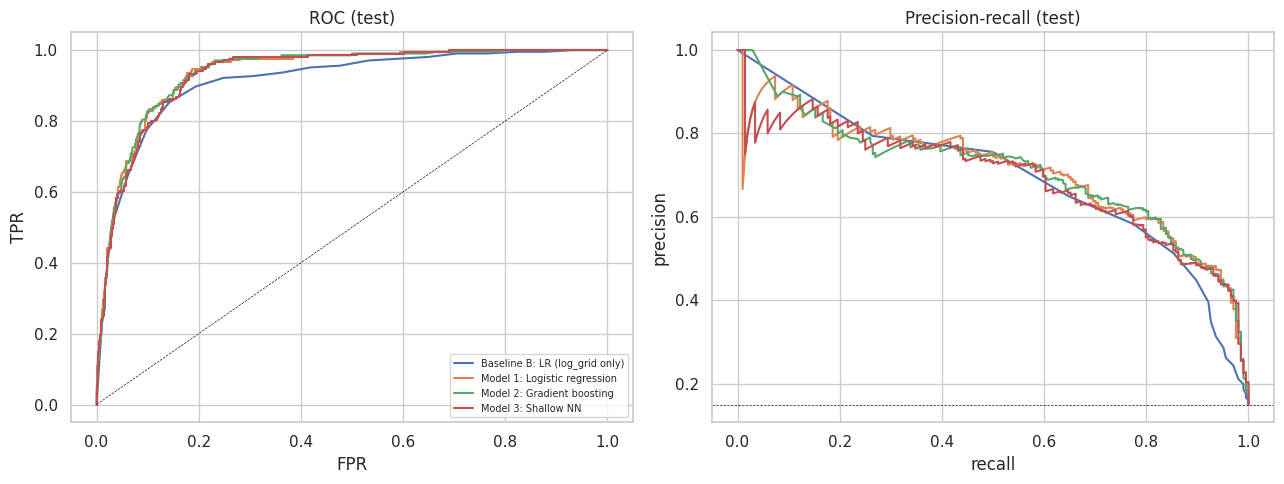

In [65]:
res = pd.DataFrame(results).T; res.index.names = ["model", "split"]
cols = ["roc_auc", "pr_auc", "f1", "precision", "recall", "logloss", "top3_hit", "threshold"]
display(res[cols].round(3))
print("Test only:"); display(res.xs("test", level="split")[cols].round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for name in probs:
    fpr, tpr, _ = roc_curve(yte, probs[name]["test"]); axs[0].plot(fpr, tpr, label=name)
    pr, rc, _ = precision_recall_curve(yte, probs[name]["test"]); axs[1].plot(rc, pr, label=name)
axs[0].plot([0, 1], [0, 1], "k--", lw=.5); axs[0].set(xlabel="FPR", ylabel="TPR", title="ROC (test)")
axs[1].axhline(yte.mean(), color="k", ls="--", lw=.5); axs[1].set(xlabel="recall", ylabel="precision", title="Precision-recall (test)")
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 4.3 Discussion
- **Versus the baselines:** the grid ≤ 3 rule reaches F1 **0.649** / PR-AUC **0.647** on test; logistic regression on `log_grid` only reaches the same (F1 0.649, PR-AUC 0.647, ROC-AUC 0.914, logloss 0.247). Adding form and circuit features gives ΔROC-AUC **+0.023** (0.914 → 0.937) and ΔPR-AUC **+0.063** (0.647 → 0.710) for logistic regression, and similar gains for the other models (gradient boosting +0.022 / +0.060). So the engineered features add value beyond the starting grid.
- **Model comparison:** there is no single winner. The shallow NN is best on validation logloss (0.214, vs 0.216 gradient boosting and 0.224 logistic regression). On test, logistic regression is best on ROC-AUC (0.937) and PR-AUC (0.710), and gradient boosting on F1 (0.696) and logloss (0.222). Differences between the three models are **small** (≤ 0.003 ROC-AUC, ≤ 0.016 PR-AUC on test) relative to test noise (≈ 200 podium rows), so the models are statistically indistinguishable and the choice should rest on simplicity and interpretability: logistic regression is sufficient.
- **Why this tool:** logistic regression is the interpretable baseline; gradient boosting tests whether non-linearities/interactions (grid × circuit, penalty hump) help; the shallow NN (`<architecture>`, dropout `<x>`, L2, early stopping) tests a smooth non-linear learner. The non-linear models do not clearly beat the linear one, so the signal is mostly captured by `log_grid` plus the form features.
- **Over-fitting check:** train vs validation gap is small for both. Gradient boosting: logloss 0.213 vs 0.216, PR-AUC 0.710 vs 0.702, ROC-AUC 0.936 vs 0.936. NN: logloss 0.219 vs 0.214, PR-AUC 0.693 vs 0.717, ROC-AUC 0.931 vs 0.935. Neither over-fits; regularisation and early stopping are sufficient.
- **Generalisation to 2022-24:** ranking metrics are stable from validation to test (ROC-AUC 0.933-0.936 → 0.934-0.937, logloss within 0.009). Threshold-dependent metrics are **lower** on test (F1 0.717-0.728 → 0.669-0.696; baseline A also drops 0.712 → 0.649), which is consistent with the new regulation era and the smaller sample, but the data can't separate these causes. The NN loses the most (PR-AUC 0.717 → 0.694), so it is the least stable.
- **Threshold:** chosen on validation (max F1): 0.284 (LR), 0.302 (GB), 0.292 (NN), well below 0.5 because positives are only ≈ 14-15%. This favours recall over precision: on test, recall is 0.75-0.80 vs precision 0.58-0.62 (e.g. gradient boosting: recall 0.804, precision 0.614). The model flags more than 3 drivers per race to avoid missing podium finishers.
- **Per-race top-3 hit** shows how often the model's three highest-scored drivers are real podium finishers. On test it is 0.652 (LR), 0.642 (GB) and 0.637 (NN), versus 0.652 for the grid rule, so the models improve overall ranking quality (AUC, PR-AUC, logloss) but not the per-race top-3 selection. Most of the podium is already determined by the grid.

## 4. Predictive Modeling: Justification

### 4.1 Task and comparability
Binary classification: does a driver finish on the podium (positionOrder ≤ 3), predicted after qualifying and before the start. All models use the **same rows
and the same five features** (`log_grid`, `grid_penalty`, `circuit_fr_rate`, `team_form`, `driver_form`) from the chronological split of Part 3
(train 2003-2017, validation 2018-2021, test 2022-2024), so their scores are directly comparable.

### 4.2 Why these models
The feature set is small (5 numeric, pre-race, low-noise features), the sample is moderate (≈ 6,000 training rows, ≈ 14% positives), and the
signal is dominated by one strongly monotone variable (grid). The model families are chosen to answer three different questions:

| Model | Why it was chosen | What it tests |
|---|---|---|
| **Baseline A: rule "grid ≤ 3"** | Zero-learning reference that any real model must beat; mirrors how a fan would predict a podium | Is learning needed at all? |
| **Baseline B: logistic regression on `log_grid` only** | Same learner as Model 1 with only the starting grid | What do the engineered features (form, circuit, penalty) add *beyond the grid*? |
| **Model 1: logistic regression (all features)** | Well calibrated probabilities (good for log loss and a tuned threshold), convex so no optimisation luck, coefficients are interpretable (and SHAP/LIME-friendly in Part 5). The decile plots show each feature is monotone in podium odds, the situation a linear model in log-odds handles well | Is a simple linear model in log-odds already enough? |
| **Model 2: gradient boosting (`HistGradientBoostingClassifier`)** | Best-in-class for small tabular data; captures **non-linearities and interactions** a linear model cannot: the hump-shaped `grid_penalty`, circuit × grid effects (Q1), team form × grid. Trees need no scaling and are robust to feature redundancy. Shallow trees (depth 2-4), L2 and a minimum leaf size of 40 keep it from over-fitting a small sample | Do non-linear effects and interactions add predictive value? |
| **Model 3: shallow neural network (Keras)** | The brief's required shallow architecture: 1-2 ReLU hidden layers (8-32 units), dropout and L2 regularisation, early stopping on validation loss. A smooth non-linear learner, complementary to the piecewise-constant trees | Does a smooth non-linear function of the same features beat the trees and the linear model? |

**Why not deeper or more complex models.** With ≈ 6,000 rows and 5 features, a deeper network or a large ensemble would over-fit and add no information; the
shallow depth is justified by the sample size. Random forest and SVM were not needed: boosting covers tree-based non-linearity, and
the NN covers smooth non-linearity.

**Why not predict the exact position.** Out of scope for this milestone; the binary target also matches how the features are built (podium rate
histories).

### 4.3 Training and selection protocol (no test-set use)
- **Hyper-parameters** are selected on the **validation set** after fitting on the training set, using validation **log loss** (a proper scoring rule, smoother than PR-AUC with
  only ≈ 240 validation podiums): logistic regression `C ∈ {0.01, 0.1, 1, 10}`; boosting `max_depth ∈ {2,3,4}`, `learning_rate ∈ {0.03, 0.1}`,
  `max_iter ∈ {100, 300}`; NN hidden layers `{(8), (16), (32,16)}` × dropout `{0, 0.2}`.
- **Decision threshold** of each model = the probability that maximises **F1 on the validation set**. The default 0.5 is inappropriate for a ≈ 14% positive class.
- **Imbalance** (≈ 3 podiums per race) is mild, so no resampling or class weights are used (Part 3 showed reweighting leaves ranking unchanged but distorts probabilities).
  It is handled through PR-AUC and F1 reporting and the validation-tuned threshold.
- **Test (2022-2024)** is scored once with the models fitted on train only (the threshold belongs to the model it was tuned for, so no refit on train+validation).
  The NN uses the validation set for early stopping only.
- Scaling (standardisation) is fitted on the training data only; seeds are fixed (42).

### 4.4 Metrics and why each is reported
| Metric | Role here |
|---|---|
| ROC-AUC | overall separation of podium vs non-podium drivers |
| PR-AUC | main ranking metric: more informative than ROC-AUC when the positive class is rare (≈ 14%) |
| F1 (with precision and recall) | quality at the validation-tuned threshold; balances false podium calls against missed podiums |
| Log loss | probability quality (calibration); the selection criterion |
| Per-race top-3 hit rate | how many of the 3 highest-scored drivers in a race are real podium finishers (matches the "pick the podium" use case) |

### 4.5 Results and justification against the baselines
Test results (2022-2024, thresholds and hyper-parameters fixed on validation):

| Model | ROC-AUC | PR-AUC | F1 | Precision | Recall | Log loss | Top-3 hit |
|---|---|---|---|---|---|---|---|
| Baseline A: grid ≤ 3 | 0.914 | 0.647 | 0.649 | 0.650 | 0.647 | n/a | 0.652 |
| Baseline B: LR (log_grid) | 0.914 | 0.647 | 0.649 | 0.650 | 0.647 | 0.247 | 0.652 |
| Model 1: Logistic regression | 0.937 | 0.710 | 0.680 | 0.622 | 0.750 | 0.227 | 0.652 |
| Model 2: Gradient boosting | 0.936 | 0.707 | 0.696 | 0.614 | 0.804 | 0.222 | 0.642 |
| Model 3: Shallow NN | 0.934 | 0.694 | 0.669 | 0.579 | 0.794 | 0.223 | 0.637 |
(⚠ values from the 7-feature run; refresh after the 5-feature rerun)

- **Versus the baselines.** Baselines A and B are identical, because a logistic regression on the grid alone ranks drivers by grid and its tuned threshold (0.405) equals "grid ≤ 3".
  Every learned model clearly beats them: ROC-AUC +0.02, PR-AUC +0.05 to +0.06, F1 +0.02 to +0.05, log loss −0.02 (0.247 → 0.222-0.227). The form and circuit features therefore add predictive value beyond the starting grid, consistent with the Part 3 ablation.
- **Linear vs non-linear.** Gradient boosting and the NN do not improve on logistic regression in a meaningful way (ΔROC-AUC ≤ 0.003, ΔPR-AUC within ±0.016, with only 204 test podiums). The relationships are close to monotone in log-odds once the features are built,
  so non-linear capacity adds little; the simple, calibrated, interpretable model is competitive.
- **Over-fitting.** Train and validation scores are close for all three models (e.g. PR-AUC 0.688 / 0.709 for logistic regression, 0.710 / 0.702 for boosting,
  0.693 / 0.717 for the NN), so the regularised, shallow models do not over-fit.
- **Generalisation.** Test scores are on par with validation (ROC-AUC 0.934-0.937 vs 0.933-0.936) despite the 2022 regulation change; even the grid rule scores higher on validation and test
  than on train, so the later seasons are not harder to predict.
- **Threshold behaviour.** The F1-optimal thresholds (0.28-0.30) favour recall (0.75-0.80) over precision (0.58-0.62), as expected for a rare positive class.
- **Ranking limit.** The per-race top-3 hit rate does not improve on the grid rule (0.64-0.65 vs 0.652): the extra features improve probability quality and recall,
  not which three drivers are ranked first, since the starting grid already determines the leading positions.
- **Selected model.** By the pre-declared rule (lowest validation log loss), the shallow NN (one hidden layer of 8 units, no dropout, validation log loss 0.2139) is selected.
  Its advantage over boosting (0.2163) and logistic regression (0.2241) is small and the three models are statistically indistinguishable on test, so the
  choice is not driven by the test set; the simpler models remain valid alternatives.

### 4.6 Limitations
Only pre-race information is used, so the ceiling is limited (the top-3 hit rate stays near 0.7, mostly set by the grid). The test sample is small, so metric
differences between models of about 0.01 are not significant. Team strength and driver skill are captured only through rolling podium rates.

## 5. Experiment: feature-group ablation
Remove one feature group at a time, retrain each model with its **tuned hyper-parameters from Part 4** (unchanged), re-tune the F1 threshold on validation, and measure the drop versus the full model. Validation and test are both reported; nothing is selected on test.


=== VAL (negative Δ = performance lost without the group; for log loss, positive Δ = worse) ===


n_features  roc_auc  pr_auc  \
model               removed                                                   
Logistic regression full model                           7    0.933   0.709   
                    − grid & qualifying                  5    0.890   0.579   
                    − circuit history                    6    0.933   0.709   
                    − team form                          6    0.932   0.715   
                    − driver form                        6    0.931   0.696   
                    − all form (team + driver)           5    0.924   0.695   
Gradient boosting   full model                           7    0.936   0.702   
                    − grid & qualifying                  5    0.896   0.590   
                    − circuit history                    6    0.937   0.711   
                    − team form                          6    0.934   0.703   
                    − driver form                        6    0.935   0.700   
                    − all form (team + driver)           5    0.922   0.698   
Shallow NN          full model                           7    0.935   0.717   
                    − grid & qualifying                  5    0.896   0.614   
                    − circuit history                    6    0.935   0.711   
                    − team form                          6    0.931   0.698   
                    − driver form                        6    0.932   0.692   
                    − all form (team + driver)           5    0.925   0.688   

                                                   f1  logloss  d_roc_auc  \
model               removed                                                 
Logistic regression full model                  0.728    0.224      0.000   
                    − grid & qualifying         0.679    0.272     -0.043   
                    − circuit history           0.729    0.224      0.000   
                    − team form                 0.723    0.225     -0.001   
                    − driver form               0.719    0.226     -0.001   
                    − all form (team + driver)  0.719    0.235     -0.008   
Gradient boosting   full model                  0.717    0.216      0.000   
                    − grid & qualifying         0.680    0.263     -0.040   
                    − circuit history           0.716    0.216      0.001   
                    − team form                 0.723    0.218     -0.002   
                    − driver form               0.719    0.217     -0.001   
                    − all form (team + driver)  0.716    0.233     -0.015   
Shallow NN          full model                  0.725    0.214      0.000   
                    − grid & qualifying         0.665    0.259     -0.039   
                    − circuit history           0.720    0.216      0.000   
                    − team form                 0.709    0.220     -0.004   
                    − driver form               0.709    0.220     -0.003   
                    − all form (team + driver)  0.719    0.229     -0.010   

                                                d_pr_auc   d_f1  d_logloss  
model               removed                                                 
Logistic regression full model                     0.000  0.000      0.000  
                    − grid & qualifying           -0.130 -0.050      0.048  
                    − circuit history              0.000  0.001      0.000  
                    − team form                    0.006 -0.005      0.001  
                    − driver form                 -0.013 -0.009      0.002  
                    − all form (team + driver)    -0.014 -0.009      0.011  
Gradient boosting   full model                     0.000  0.000      0.000  
                    − grid & qualifying           -0.112 -0.036      0.046  
                    − circuit history              0.009 -0.001     -0.000  
                    − team form                    0.002  0.006      0.002  
  


=== TEST (negative Δ = performance lost without the group; for log loss, positive Δ = worse) ===


n_features  roc_auc  pr_auc  \
model               removed                                                   
Logistic regression full model                           7    0.937   0.710   
                    − grid & qualifying                  5    0.876   0.517   
                    − circuit history                    6    0.937   0.710   
                    − team form                          6    0.935   0.701   
                    − driver form                        6    0.937   0.706   
                    − all form (team + driver)           5    0.922   0.683   
Gradient boosting   full model                           7    0.936   0.707   
                    − grid & qualifying                  5    0.878   0.505   
                    − circuit history                    6    0.936   0.703   
                    − team form                          6    0.935   0.711   
                    − driver form                        6    0.935   0.700   
                    − all form (team + driver)           5    0.918   0.672   
Shallow NN          full model                           7    0.934   0.694   
                    − grid & qualifying                  5    0.876   0.522   
                    − circuit history                    6    0.937   0.711   
                    − team form                          6    0.933   0.705   
                    − driver form                        6    0.931   0.694   
                    − all form (team + driver)           5    0.918   0.673   

                                                   f1  logloss  d_roc_auc  \
model               removed                                                 
Logistic regression full model                  0.680    0.227      0.000   
                    − grid & qualifying         0.548    0.306     -0.060   
                    − circuit history           0.677    0.228      0.000   
                    − team form                 0.677    0.230     -0.002   
                    − driver form               0.691    0.227      0.000   
                    − all form (team + driver)  0.659    0.244     -0.014   
Gradient boosting   full model                  0.696    0.222      0.000   
                    − grid & qualifying         0.568    0.289     -0.058   
                    − circuit history           0.679    0.223     -0.000   
                    − team form                 0.690    0.224     -0.001   
                    − driver form               0.678    0.225     -0.001   
                    − all form (team + driver)  0.642    0.243     -0.018   
Shallow NN          full model                  0.669    0.223      0.000   
                    − grid & qualifying         0.545    0.287     -0.057   
                    − circuit history           0.667    0.221      0.003   
                    − team form                 0.656    0.225     -0.000   
                    − driver form               0.623    0.227     -0.002   
                    − all form (team + driver)  0.639    0.243     -0.016   

                                                d_pr_auc   d_f1  d_logloss  
model               removed                                                 
Logistic regression full model                     0.000  0.000      0.000  
                    − grid & qualifying           -0.194 -0.132      0.079  
                    − circuit history             -0.000 -0.003      0.000  
                    − team form                   -0.009 -0.003      0.003  
                    − driver form                 -0.005  0.011     -0.000  
                    − all form (team + driver)    -0.028 -0.021      0.017  
Gradient boosting   full model                     0.000  0.000      0.000  
                    − grid & qualifying           -0.202 -0.128      0.067  
                    − circuit history             -0.004 -0.018      0.001  
                    − team form                    0.004 -0.006      0.002  
  

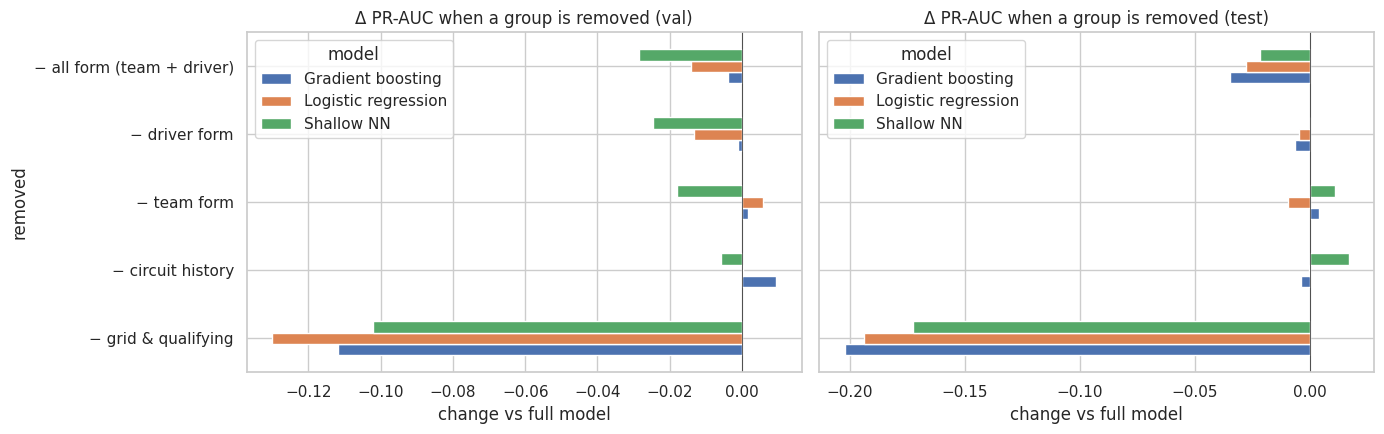

In [66]:
from sklearn.base import clone

ABL = {                                            # group -> features removed together
    "grid & qualifying": ["log_grid", "grid_penalty"],
    "circuit history":   ["circuit_fr_rate"],
    "team form":         ["team_form"],
    "driver form":       ["driver_form"],
    "all form (team + driver)": ["team_form", "driver_form"],
}
makers = {"Logistic regression": lambda: clone(lr),
          "Gradient boosting":   lambda: clone(gb),
          "Shallow NN":          lambda: KerasNN(nn.hidden, nn.dropout, nn.l2, nn.lr)}

def fit_predict(name, cols):
    m = makers[name]()
    m.fit(tr[cols], ytr, va[cols], yva) if name == "Shallow NN" else m.fit(tr[cols], ytr)
    return {s: m.predict_proba(d[cols])[:, 1] for s, d in [("val", va), ("test", te)]}

variants = [("full model", FEATURES)] + [(f"− {g}", [f for f in FEATURES if f not in fs]) for g, fs in ABL.items()]
rows = []
for name in makers:
    for label, cols in variants:
        p = fit_predict(name, cols); t = best_threshold(yva, p["val"])        # threshold re-tuned on validation
        for s, d, y in [("val", va, yva), ("test", te, yte)]:
            rows.append(dict(model=name, removed=label, split=s, n_features=len(cols), **metrics(d, y, p[s], t)))
abl = pd.DataFrame(rows)

full = abl[abl.removed == "full model"].set_index(["model", "split"])
for m in ["roc_auc", "pr_auc", "f1", "logloss"]:                              # change vs the full model
    abl["d_" + m] = abl[m].values - full.loc[list(zip(abl.model, abl.split)), m].values
show = ["n_features", "roc_auc", "pr_auc", "f1", "logloss", "d_roc_auc", "d_pr_auc", "d_f1", "d_logloss"]
for s in ["val", "test"]:
    print(f"\n=== {s.upper()} (negative Δ = performance lost without the group; for log loss, positive Δ = worse) ===")
    display(abl[abl.split == s].set_index(["model", "removed"])[show].round(3))

# %%
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, s in zip(axs, ["val", "test"]):
    piv = abl[(abl.split == s) & (abl.removed != "full model")].pivot(index="removed", columns="model", values="d_pr_auc")
    piv = piv.loc[[f"− {g}" for g in ABL]]; piv.plot.barh(ax=ax); ax.axvline(0, color="k", lw=.5)
    ax.set_title(f"Δ PR-AUC when a group is removed ({s})"); ax.set_xlabel("change vs full model")
plt.tight_layout(); plt.show()

### Reading the ablation
- **Grid & qualifying** is the dominant group: removing it costs ΔPR-AUC **−0.10 to −0.13** on validation (LR −0.130, GB −0.112, NN −0.102) and **−0.17 to −0.20** on test (LR −0.194, GB −0.202, NN −0.172). ΔROC-AUC is −0.039 to −0.043 on validation and −0.057 to −0.060 on test, and logloss worsens by +0.046 to +0.048 on validation and +0.064 to +0.079 on test. This is the largest drop for every model, confirming that the starting position carries most of the signal. Without it, the models still reach ROC-AUC ≈ 0.88-0.90, so the remaining features (form, penalty) are not uninformative.
- **Form (team + driver):** removing both costs ΔPR-AUC −0.014 (LR), −0.004 (GB), −0.028 (NN) on validation and −0.028 (LR), −0.035 (GB), −0.022 (NN) on test. ΔROC-AUC is −0.008 to −0.015 on validation and −0.014 to −0.018 on test, and logloss worsens by +0.011 to +0.017 (validation) and +0.017 to +0.021 (test). The effect has the same sign for all models and is clearly above noise on test. Team form alone and driver form alone cost less and are not stable in sign (e.g. test ΔPR-AUC for team form: LR −0.009, GB +0.004, NN +0.011). The two features partly substitute for each other, so their value shows up when both are removed. They carry information not contained in the grid (car pace and driver skill).
- **Circuit history:** ΔPR-AUC +0.000 (LR), +0.009 (GB), −0.006 (NN) on validation; −0.000 (LR), −0.004 (GB), +0.017 (NN) on test. **Negligible and inconsistent in sign**: removing it does not hurt, and the NN test PR-AUC even improves, so there is no evidence the feature helps. This is consistent with the Part 3 ablation (no log-loss gain).
- **Agreement across models:** the ranking of group importance is **the same** for logistic regression, boosting and the NN: grid & qualifying ≫ form (both) > team or driver form alone ≈ circuit history ≈ 0. The conclusions do not depend on the learner. The order of team vs driver form individually differs between models and splits, so it should not be interpreted.
- **Noise:** changes smaller than about 0.01 PR-AUC (≈ 200 test podiums) are not distinguishable from noise. Only the grid & qualifying and the combined form removals clearly exceed this consistently across models on test. Logloss and ROC-AUC are less noisy than PR-AUC, which is why GB's combined-form drop on validation (ΔPR-AUC −0.004) still shows up as ΔROC-AUC −0.015 and Δlogloss +0.017. Validation and test agree in direction for all main conclusions.

# 6. Model Explainability (XAI)
**Important: these explanations describe what the *model* relies on, not what *causes* podium finishes.** A feature can be important because it correlates with, or proxies for, something else (e.g. `team_form` stands in for car quality, `log_grid` for qualifying pace).
Feature importance is **not** a causal effect: it only says the model uses the feature to predict.

In [67]:
import shap, lime, lime.lime_tabular
from sklearn.inspection import permutation_importance
from IPython.display import HTML, display

NAME = "Gradient boosting"      # explained model; or "Logistic regression" / "Shallow NN"
model = {"Logistic regression": lr, "Gradient boosting": gb, "Shallow NN": nn}[NAME]
f = lambda X: model.predict_proba(pd.DataFrame(X, columns=FEATURES))[:, 1]       # P(podium) = class 1 output (2D, no class axis)
print("Explaining:", NAME)

Explaining: Gradient boosting


### 6.1 Global: permutation importance (held-out test set)

Global permutation importances (drop in test PR-AUC when the feature is shuffled):
log_grid          : 0.4023 ± 0.0190
driver_form       : 0.0532 ± 0.0190
team_form         : 0.0221 ± 0.0125
circuit_fr_rate   : 0.0017 ± 0.0029
is_home           : 0.0012 ± 0.0024
team_mech_rate    : 0.0011 ± 0.0049
grid_penalty      : 0.0009 ± 0.0026


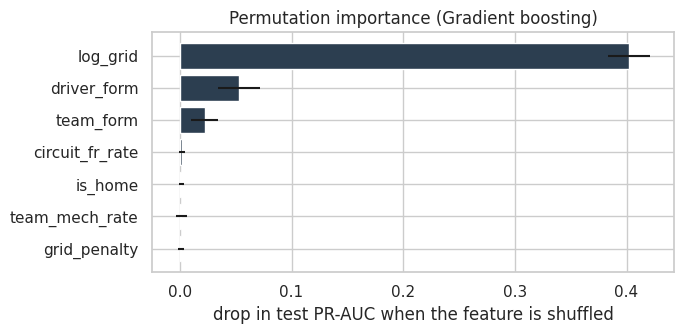

In [68]:
pi = permutation_importance(model, Xte, yte, n_repeats=30, random_state=SEED,
                            scoring=lambda est, X, y: average_precision_score(y, est.predict_proba(X)[:, 1]))
print("Global permutation importances (drop in test PR-AUC when the feature is shuffled):")
for i in pi.importances_mean.argsort()[::-1]:
    print(f"{FEATURES[i]:<18}: {pi.importances_mean[i]:.4f} ± {pi.importances_std[i]:.4f}")

order = pi.importances_mean.argsort()
plt.figure(figsize=(7, 3.5), dpi=100)
plt.barh(np.array(FEATURES)[order], pi.importances_mean[order], xerr=pi.importances_std[order], color="#2c3e50")
plt.xlabel("drop in test PR-AUC when the feature is shuffled"); plt.title(f"Permutation importance ({NAME})")
plt.tight_layout(); plt.show()

## 6.2 Global: SHAP beeswarm
`HistGradientBoostingClassifier` is not supported by `TreeExplainer`, so the model-agnostic `shap.Explainer` is used on the P(podium) function (class 1), against a background of 100 training rows.

ExactExplainer explainer: 501it [00:49,  7.99it/s]                         


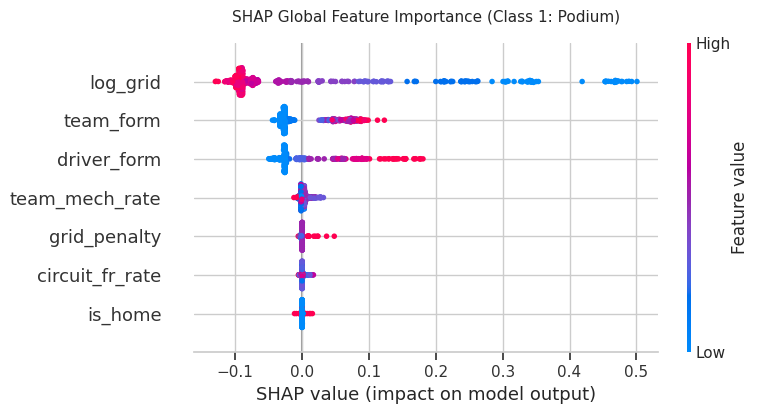

In [69]:
bg = shap.sample(Xtr, 100, random_state=SEED)
explainer = shap.Explainer(f, bg)
Xs = Xte.sample(min(500, len(Xte)), random_state=SEED)
shap_vals = explainer(Xs)

plt.figure(figsize=(9, 4.5), dpi=100)
shap.plots.beeswarm(shap_vals, max_display=len(FEATURES), show=False)
plt.title("SHAP Global Feature Importance (Class 1: Podium)", fontsize=11, pad=15); plt.tight_layout(); plt.show()

## 6.3 Local: SHAP waterfall and LIME for single predictions
Two test rows: the **most confident correct podium** and the **biggest surprise podium** (lowest predicted probability among real podium finishers).


=== confident hit: raceId 1098, driverId 830, year 2023, predicted P(podium) = 0.869, actual podium = 1 ===
{'log_grid': 0.0, 'grid_penalty': 0.0, 'circuit_fr_rate': 0.644, 'is_home': 0.0, 'team_form': 0.432, 'driver_form': 0.556, 'team_mech_rate': 0.114}


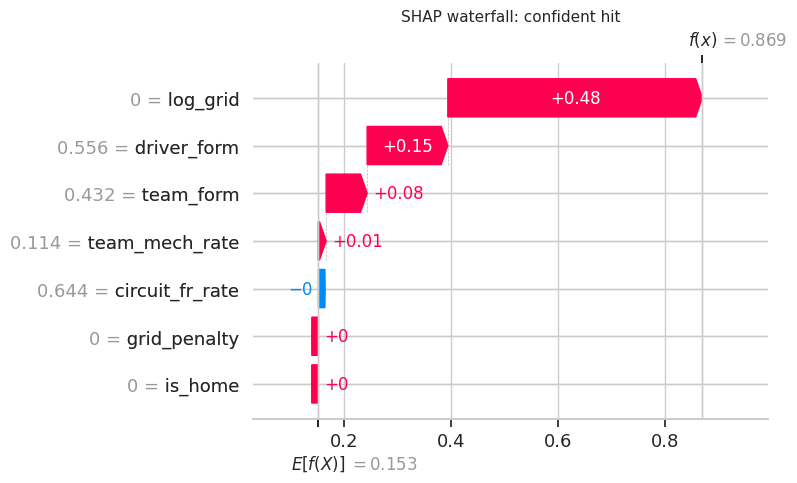


=== surprise podium: raceId 1111, driverId 842, year 2023, predicted P(podium) = 0.008, actual podium = 1 ===
{'log_grid': 2.485, 'grid_penalty': 0.0, 'circuit_fr_rate': 0.608, 'is_home': 0.0, 'team_form': 0.068, 'driver_form': 0.056, 'team_mech_rate': 0.196}


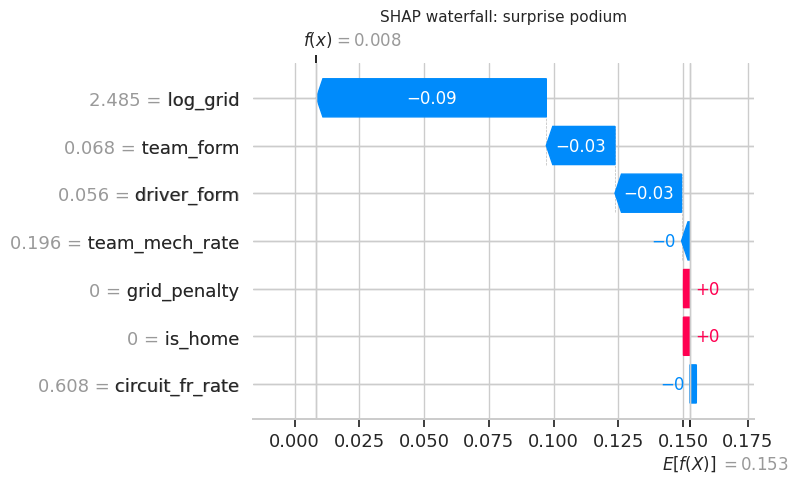

In [70]:
p_te = pd.Series(f(Xte), index=Xte.index); pod = te[yte == 1]
hit_idx, surprise_idx = p_te[pod.index].idxmax(), p_te[pod.index].idxmin()

lime_exp = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(Xtr), feature_names=FEATURES, class_names=["No Podium", "Podium"],
    mode="classification", discretize_continuous=True, random_state=SEED)

for tag, i in [("confident hit", hit_idx), ("surprise podium", surprise_idx)]:
    r = te.loc[i]
    print(f"\n=== {tag}: raceId {int(r.raceId)}, driverId {int(r.driverId)}, year {int(r.year)}, "
          f"predicted P(podium) = {p_te[i]:.3f}, actual podium = {int(r.podium)} ===")
    print(Xte.loc[i].round(3).to_dict())
    plt.figure(figsize=(8, 4.5), dpi=100)
    shap.plots.waterfall(explainer(Xte.loc[[i]])[0], max_display=len(FEATURES), show=False)
    plt.title(f"SHAP waterfall: {tag}", fontsize=11); plt.tight_layout(); plt.show()
    e = lime_exp.explain_instance(Xte.loc[i].values, lambda a: model.predict_proba(pd.DataFrame(a, columns=FEATURES)),
                                  num_features=len(FEATURES))
    # default LIME HTML block, in an unconstrained, horizontally scrollable container
    display(HTML(f'<div style="width: 100%; min-width: 850px; overflow-x: auto; padding: 10px; background-color: #ffffff;">{e.as_html()}</div>'))